
<div style="background:linear-gradient(135deg,#0F2044 0%,#1A4A8A 55%,#2E86DE 100%);
            padding:55px 45px;border-radius:14px;color:white;">
  <h1 style="font-size:2.5em;margin:0 0 6px 0;color:#0DC0C0;letter-spacing:3px;">
    🎯 TP 2 — TÂCHES DE LA VISION PAR ORDINATEUR
  </h1>
  <h2 style="font-size:1.35em;font-weight:300;margin:0 0 6px 0;color:white;">
    Classification · Détection d'objets · Segmentation — M2 Informatique
  </h2>
  <p style="color:#B0C4DE;font-size:0.95em;margin:0 0 28px 0;font-style:italic;">
    Suite directe du TP1 (Prétraitement) — les pipelines du TP1 sont réutilisés ici
  </p>
  <hr style="border-color:#2E86DE55;margin:0 0 22px 0;">
  <p style="color:#E8ECF4;line-height:1.9;margin:0 0 22px 0;font-size:1.05em;">
    Ce TP met en pratique les <strong style="color:#0DC0C0;">trois grandes tâches</strong> de la vision par ordinateur.
    Vous implémenterez chaque tâche <strong>depuis zéro</strong> avec NumPy et OpenCV, puis comparerez
    avec les APIs haut-niveau (scikit-learn, torchvision).
  </p>
  <div style="display:grid;grid-template-columns:repeat(4,1fr);gap:12px;">
    <div style="background:#ffffff18;border-radius:8px;padding:10px 14px;border-left:3px solid #F4845F;">
      <div style="font-size:1.4em;">🏷️</div>
      <div style="font-size:0.85em;font-weight:bold;color:#F4845F;">3 Modules</div>
      <div style="font-size:0.8em;color:#B0C4DE;">Class · Détect · Seg</div>
    </div>
    <div style="background:#ffffff18;border-radius:8px;padding:10px 14px;border-left:3px solid #F97316;">
      <div style="font-size:1.4em;">🏋️</div>
      <div style="font-size:0.85em;font-weight:bold;color:#F97316;">18 Exercices</div>
      <div style="font-size:0.8em;color:#B0C4DE;">guidés avec hints</div>
    </div>
    <div style="background:#ffffff18;border-radius:8px;padding:10px 14px;border-left:3px solid #22C55E;">
      <div style="font-size:1.4em;">🔬</div>
      <div style="font-size:0.85em;font-weight:bold;color:#22C55E;">Demos complètes</div>
      <div style="font-size:0.8em;color:#B0C4DE;">NumPy · OpenCV · sklearn</div>
    </div>
    <div style="background:#ffffff18;border-radius:8px;padding:10px 14px;border-left:3px solid #9B59B6;">
      <div style="font-size:1.4em;">🏆</div>
      <div style="font-size:0.85em;font-weight:bold;color:#9B59B6;">Projet final</div>
      <div style="font-size:0.8em;color:#B0C4DE;">Pipeline bout-en-bout</div>
    </div>
  </div>
</div>


---
## ⚙️ Installation & imports

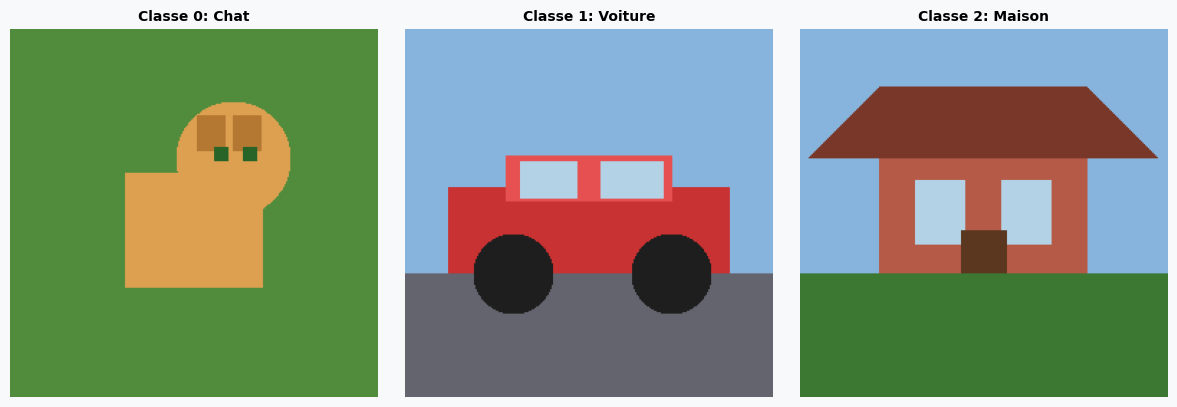

Environnement prêt. Images de base : [(256, 256, 3), (256, 256, 3), (256, 256, 3)]


In [27]:
# ── Installation (décommentez si nécessaire) ──────────────────────────
# !pip install numpy matplotlib opencv-python pillow scikit-learn scikit-image scipy
# !pip install torch torchvision   # pour les exercices PyTorch (optionnel)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap
import cv2
from PIL import Image
from scipy import ndimage as ndi
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                              accuracy_score, average_precision_score)
from sklearn.cluster import KMeans
from skimage import feature, segmentation, color, measure, filters, morphology
from skimage.feature import hog, local_binary_pattern
from skimage.segmentation import slic, mark_boundaries, watershed, felzenszwalb
import warnings
warnings.filterwarnings("ignore")

# ── Palette & helpers ─────────────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "#F8F9FA", "axes.facecolor": "#FFFFFF",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold",
})
ORANGE, GREEN, PURPLE = "#F4845F", "#27AE60", "#8E44AD"
BLUE, TEAL, RED = "#1B6CA8", "#0ABFBC", "#E74C3C"

def show_grid(imgs, titles, ncols=4, figsize=None, cmaps=None):
    nrows = (len(imgs) + ncols - 1) // ncols
    if figsize is None: figsize = (4*ncols, 3.5*nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).ravel()
    for i, (ax, img, title) in enumerate(zip(axes, imgs, titles)):
        cmap = (cmaps[i] if cmaps else None) if cmaps else (
            "gray" if len(np.array(img).shape) == 2 else None)
        ax.imshow(np.array(img).clip(0,255).astype(np.uint8) if np.array(img).max()>1 else np.array(img),
                  cmap=cmap)
        ax.set_title(title, fontsize=10); ax.axis("off")
    for ax in axes[len(imgs):]: ax.set_visible(False)
    plt.tight_layout(); plt.show()

# ── Génération des images synthétiques réutilisées tout au long du TP ─
np.random.seed(42)
H, W = 256, 256

def make_scene(label=0):
    "Génère une scène synthétique : 0=chat, 1=voiture, 2=maison"
    img = np.zeros((H, W, 3), dtype=np.uint8)
    if label == 0:   # Chat (orange sur fond vert)
        img[:] = [80, 140, 60]
        # Corps
        img[100:180, 80:176] = [220, 160, 80]
        # Tête
        for y in range(H):
            for x in range(W):
                if (y-90)**2 + (x-155)**2 < 40**2:
                    img[y,x] = [220, 160, 80]
        img[60:85, 130:150] = [180, 120, 50]   # oreille gauche
        img[60:85, 155:175] = [180, 120, 50]   # oreille droite
        img[82:92, 142:152] = [40, 100, 40]    # yeux
        img[82:92, 162:172] = [40, 100, 40]
    elif label == 1: # Voiture (rouge sur fond gris)
        img[:170] = [135, 180, 220]            # ciel
        img[170:] = [100, 100, 110]            # route
        img[110:170, 30:226] = [200, 50, 50]   # carrosserie
        img[88:120, 70:186] = [230, 80, 80]    # toit
        img[92:118, 80:120] = [180, 210, 230]  # vitre G
        img[92:118, 136:180] = [180, 210, 230] # vitre D
        for cx in [75, 185]:                   # roues
            for y in range(H):
                for x in range(W):
                    if (y-170)**2 + (x-cx)**2 < 28**2:
                        img[y,x] = [30, 30, 30]
    else:            # Maison (brique sur fond bleu)
        img[:170] = [135, 180, 220]
        img[170:] = [60, 120, 50]
        img[90:170, 55:200] = [180, 90, 70]    # murs
        for i in range(50):                    # toit triangulaire
            s, e = max(0,55-i), min(W,200+i)
            img[40+i, s:e] = [120, 55, 40]
        img[105:150, 80:115] = [180, 210, 230] # fenêtre G
        img[105:150, 140:175] = [180, 210, 230]# fenêtre D
        img[140:170, 112:144] = [90, 55, 30]  # porte
    return img

CLASSES = ["Chat", "Voiture", "Maison"]
SCENES  = [make_scene(i) for i in range(3)]

show_grid(SCENES, [f"Classe {i}: {CLASSES[i]}" for i in range(3)],
          ncols=3, figsize=(12, 4))
print("Environnement prêt. Images de base :", [s.shape for s in SCENES])



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #F4845F;">
  <h1 style="color:#F4845F;margin:0;font-size:1.65em;">🏷️ Module 1 — Classification d'images</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Extraire des descripteurs · SVM · k-NN · CNN features · Métriques</p>
</div>



### 📖 Rappel théorique

La **classification** assigne une image à une classe parmi C possibles :

$$f_\theta : I \in \mathbb{R}^{H \times W \times 3} \longrightarrow \hat{y} \in \{0, 1, \ldots, C-1\}$$

#### Pipeline classique (avant deep learning)

```
Image  →  Prétraitement  →  Extraction de features  →  Classifieur  →  Label
              (TP1)           (HOG, LBP, couleur)      (SVM, kNN)
```

#### Descripteurs classiques

| Descripteur | Principe | Usage |
|-------------|----------|-------|
| **HOG** (Histogram of Oriented Gradients) | Distribution des gradients dans des cellules | Formes, contours |
| **LBP** (Local Binary Pattern) | Comparaison pixel avec ses voisins | Textures |
| **Histogramme couleur** | Distribution des valeurs par canal | Couleur dominante |
| **Pixel brut** | Aplatir l'image → vecteur | Baseline naïf |

#### Classifieurs

- **SVM** : trouve l'hyperplan de marge maximale entre classes
- **k-NN** : classe selon les k voisins les plus proches dans l'espace des features  
- **Random Forest** : ensemble d'arbres de décision

> 💡 Avec le **deep learning**, les features sont **apprises automatiquement** par le CNN — plus besoin de les définir à la main.


### 🔬 Démonstration 1.1 — Extraction de features HOG

Taille des descripteurs HOG : 8100
Taille LBP : 64
Taille histogramme couleur : 96


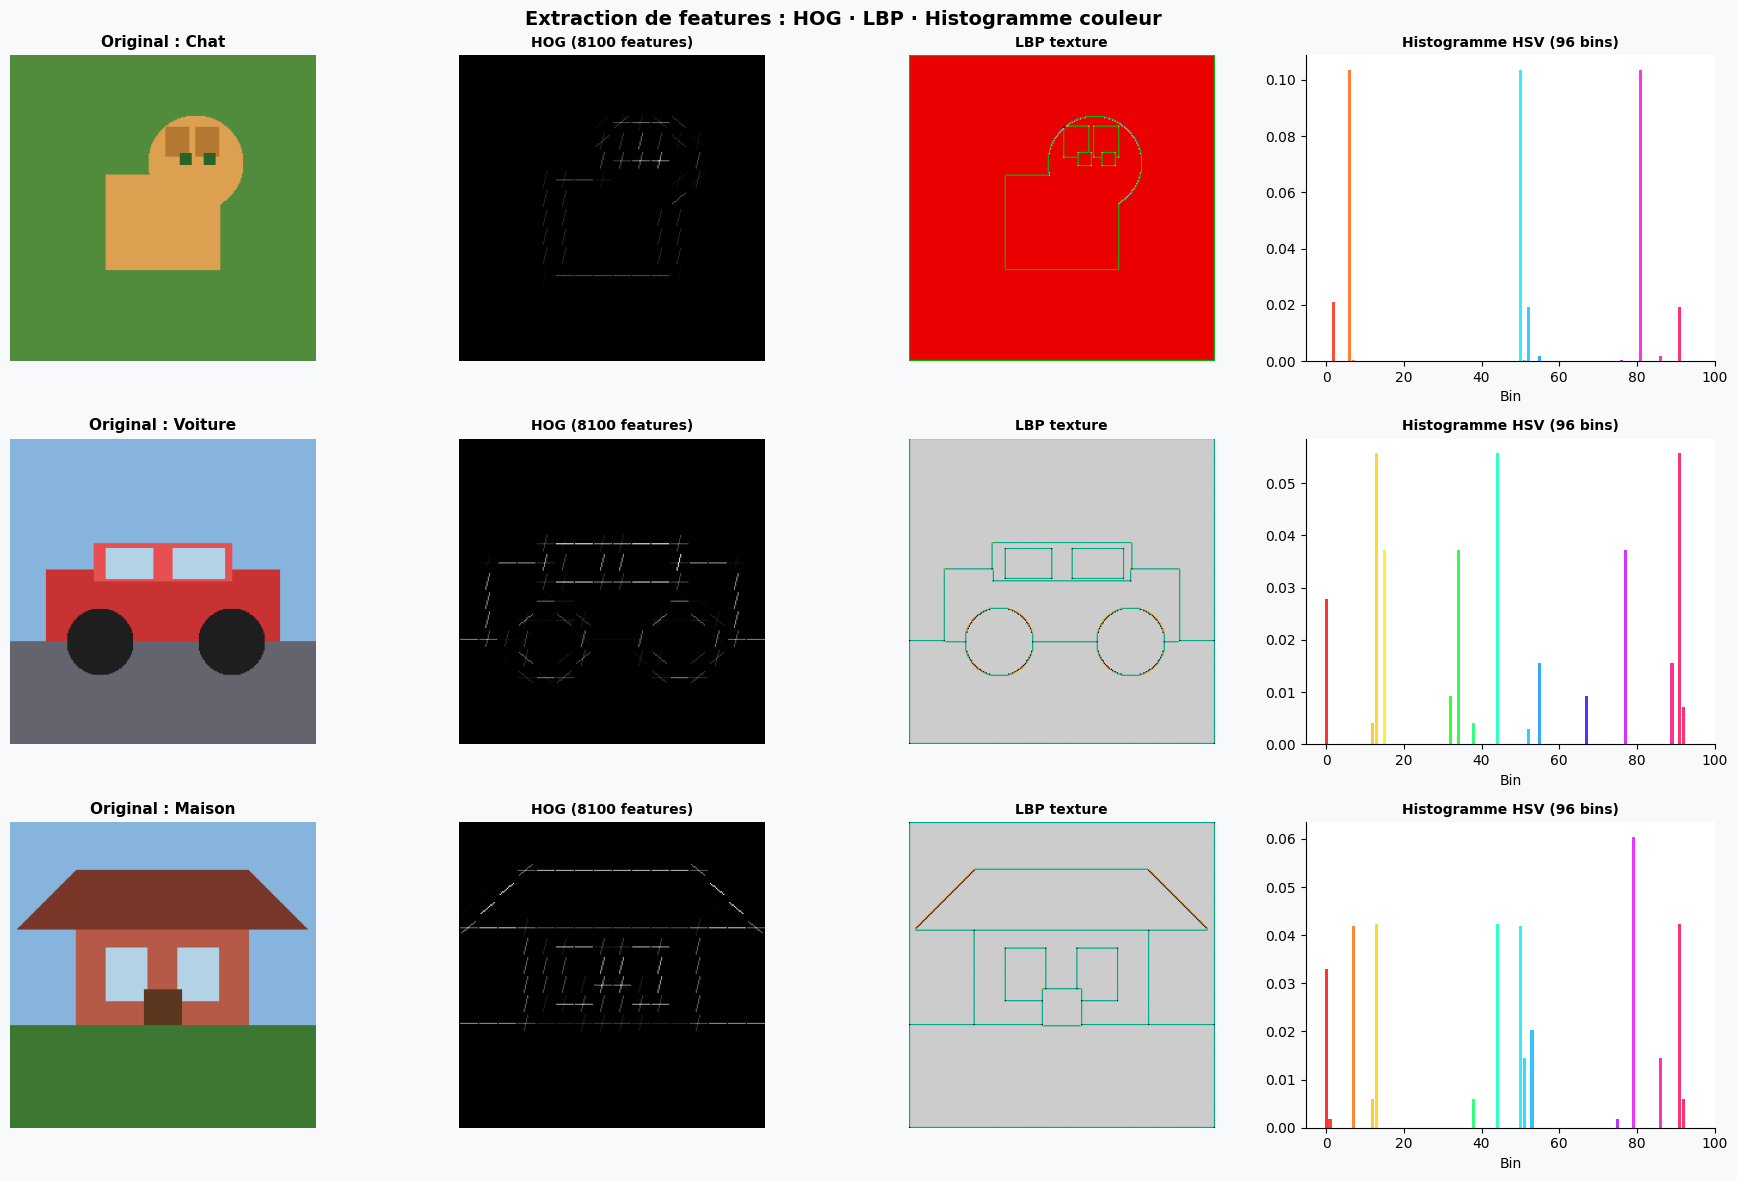

In [28]:
# ── HOG : Histogram of Oriented Gradients ─────────────────────────
def extract_hog(img, pixels_per_cell=16, cells_per_block=2, orientations=9):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    fd, hog_img = hog(gray,
                      orientations=orientations,
                      pixels_per_cell=(pixels_per_cell, pixels_per_cell),
                      cells_per_block=(cells_per_block, cells_per_block),
                      visualize=True,
                      feature_vector=True)
    return fd, hog_img

# ── LBP : Local Binary Pattern ────────────────────────────────────
def extract_lbp(img, P=8, R=1.0, n_bins=64):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    lbp  = local_binary_pattern(gray, P=P, R=R, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins,
                           range=(0, n_bins), density=True)
    return hist, lbp

# ── Histogramme couleur HSV ───────────────────────────────────────
def extract_color_hist(img, bins=32):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    feats = []
    for ch in range(3):
        h, _ = np.histogram(hsv[:,:,ch].ravel(),
                            bins=bins, range=(0,256), density=True)
        feats.append(h)
    return np.concatenate(feats)

# ── Visualisation sur les 3 classes ──────────────────────────────
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for row, (img, cls) in enumerate(zip(SCENES, CLASSES)):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    fd_hog, hog_vis = extract_hog(img)
    hist_lbp, lbp_img = extract_lbp(img)
    hist_col = extract_color_hist(img)

    # Image originale
    axes[row,0].imshow(img)
    axes[row,0].set_title(f"Original : {cls}", fontsize=11, fontweight="bold")
    axes[row,0].axis("off")

    # HOG visualization
    axes[row,1].imshow(hog_vis, cmap="gray")
    axes[row,1].set_title(f"HOG ({len(fd_hog)} features)", fontsize=10)
    axes[row,1].axis("off")

    # LBP
    axes[row,2].imshow(lbp_img, cmap="nipy_spectral")
    axes[row,2].set_title(f"LBP texture", fontsize=10)
    axes[row,2].axis("off")

    # Histogramme couleur
    colors_ch = [["#FF6B6B","#FF9999","#FFCCCC"],
                 ["#69DB7C","#99E699","#BBFFCC"],
                 ["#74C0FC","#99CCFF","#CCDDFF"]][row]
    axes[row,3].bar(range(len(hist_col)), hist_col,
                    color=plt.cm.hsv(np.linspace(0,1,len(hist_col))), alpha=0.8)
    axes[row,3].set_title(f"Histogramme HSV (96 bins)", fontsize=10)
    axes[row,3].set_xlabel("Bin")

labels_hog = [len(extract_hog(s)[0]) for s in SCENES]
print("Taille des descripteurs HOG :", labels_hog[0])
print("Taille LBP :", len(extract_lbp(SCENES[0])[0]))
print("Taille histogramme couleur :", len(extract_color_hist(SCENES[0])))

plt.suptitle("Extraction de features : HOG · LBP · Histogramme couleur",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### 🔬 Démonstration 1.2 — Dataset synthétique & classifieur SVM

Dataset : 120 images × 256×256×3
Extraction des features (patience ~10s)...
Feature matrix : (120, 8260)  (shape : n_samples × n_features)
\ ==================================================
Classifieur            Accuracy
SVM (RBF)                100.0%
k-NN (k=5)               100.0%
Random Forest            100.0%


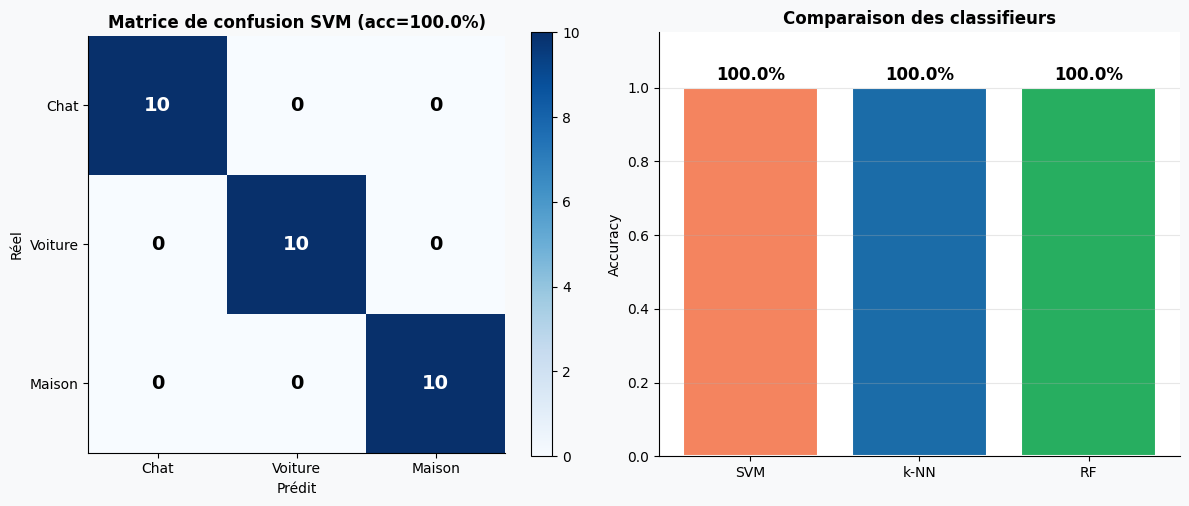

In [29]:
# ── Génération d'un dataset synthétique (augmentation du TP1) ─────
def augment_scene(img, n=30):
    "Génère n variantes augmentées d'une scène (rappel TP1)"
    variants = []
    for _ in range(n):
        v = img.copy()
        # Flip horizontal aléatoire
        if np.random.rand() > 0.5:
            v = v[:, ::-1, :]
        # Luminosité aléatoire
        b = np.random.uniform(0.6, 1.4)
        v = np.clip(v.astype(np.float32)*b, 0, 255).astype(np.uint8)
        # Bruit gaussien
        noise = np.random.randn(*v.shape) * np.random.uniform(5, 25)
        v = np.clip(v.astype(np.float32)+noise, 0, 255).astype(np.uint8)
        # Crop aléatoire puis resize
        h, w = v.shape[:2]
        top  = np.random.randint(0, 30)
        left = np.random.randint(0, 30)
        v = v[top:h-top, left:w-left]
        v = cv2.resize(v, (H, W))
        variants.append(v)
    return variants

np.random.seed(0)
N_PER_CLASS = 40
dataset_imgs, dataset_labels = [], []
for cls_idx, scene in enumerate(SCENES):
    variants = augment_scene(scene, N_PER_CLASS)
    dataset_imgs.extend(variants)
    dataset_labels.extend([cls_idx]*N_PER_CLASS)

dataset_imgs   = np.array(dataset_imgs)
dataset_labels = np.array(dataset_labels)
print(f"Dataset : {len(dataset_imgs)} images × {H}×{W}×3")

# ── Feature extraction ────────────────────────────────────────────
def extract_all_features(imgs):
    feats = []
    for img in imgs:
        hog_feat = extract_hog(img)[0]
        lbp_feat = extract_lbp(img)[0]
        col_feat = extract_color_hist(img)
        feats.append(np.concatenate([hog_feat, lbp_feat, col_feat]))
    return np.array(feats)

print("Extraction des features (patience ~10s)...")
X = extract_all_features(dataset_imgs)
y = dataset_labels
print(f"Feature matrix : {X.shape}  (shape : n_samples × n_features)")

# ── Train / Test split ────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

# ── Normalisation (StandardScaler) ───────────────────────────────
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# ── SVM ───────────────────────────────────────────────────────────
svm = SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
acc_svm    = accuracy_score(y_test, y_pred_svm)

# ── k-NN ──────────────────────────────────────────────────────────
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
acc_knn    = accuracy_score(y_test, y_pred_knn)

# ── Random Forest ─────────────────────────────────────────────────
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf  = rf.predict(X_test)
acc_rf     = accuracy_score(y_test, y_pred_rf)

print("\ " + "="*50)
print(f"{'Classifieur':<20} {'Accuracy':>10}")
print("="*50)
for name, acc in [("SVM (RBF)", acc_svm), ("k-NN (k=5)", acc_knn), ("Random Forest", acc_rf)]:
    print(f"{name:<20} {acc:>10.1%}")

# ── Matrice de confusion SVM ──────────────────────────────────────
cm = confusion_matrix(y_test, y_pred_svm)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
im = ax1.imshow(cm, cmap="Blues")
plt.colorbar(im, ax=ax1)
for i in range(3):
    for j in range(3):
        c = "white" if cm[i,j] > cm.max()*0.6 else "black"
        ax1.text(j, i, str(cm[i,j]), ha="center", va="center",
                 fontsize=14, fontweight="bold", color=c)
ax1.set_xticks(range(3)); ax1.set_xticklabels(CLASSES)
ax1.set_yticks(range(3)); ax1.set_yticklabels(CLASSES)
ax1.set_xlabel("Prédit"); ax1.set_ylabel("Réel")
ax1.set_title(f"Matrice de confusion SVM (acc={acc_svm:.1%})")

# Comparaison des classifieurs
classifiers = ["SVM", "k-NN", "RF"]
accuracies  = [acc_svm, acc_knn, acc_rf]
colors      = [ORANGE, BLUE, GREEN]
bars = ax2.bar(classifiers, accuracies, color=colors, edgecolor="white", linewidth=1.5)
for bar, acc in zip(bars, accuracies):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
             f"{acc:.1%}", ha="center", va="bottom", fontsize=12, fontweight="bold")
ax2.set_ylim(0, 1.15); ax2.set_ylabel("Accuracy")
ax2.set_title("Comparaison des classifieurs")
ax2.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()



---
### 🏋️ Exercice 1.1 — Implémenter la classification Softmax depuis zéro

**Objectif :** Implémenter un classifieur **Softmax (régression logistique multiclasse)** entraîné par descente de gradient sur nos features HOG+LBP+couleur.

**Rappel théorique :**
$$\hat{p}_k = \frac{e^{z_k}}{\sum_j e^{z_j}} \quad z = W^T x + b \quad L = -\frac{1}{N}\sum_i \log \hat{p}_{y_i}$$

**Mise à jour des poids (gradient) :**
$$\frac{\partial L}{\partial W} = \frac{1}{N} X^T (\hat{P} - Y_{onehot}) \quad \quad \theta \leftarrow \theta - \eta \cdot \nabla L$$

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Softmax stable numériquement :**
```python
def softmax(z):
    z_stable = z - z.max(axis=1, keepdims=True)   # évite overflow
    e = np.exp(z_stable)
    return e / e.sum(axis=1, keepdims=True)
```
**Hint 2 — Gradient :**
```python
# P : (N, C) probabilités prédites
# Y : (N, C) one-hot encodé
grad_W = X.T @ (P - Y_onehot) / N
grad_b = (P - Y_onehot).mean(axis=0)
```
**Hint 3 — One-hot encoding :**
```python
Y_onehot = np.eye(n_classes)[y_train]   # shape (N, C)
```
</details>


Softmax accuracy : 100.0%


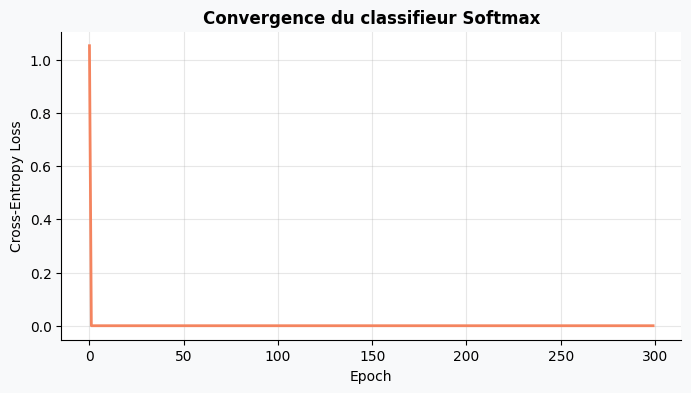

In [30]:
# ── Exercice 1.1 — À compléter ───────────────────────────────────
class SoftmaxClassifier:
    def __init__(self, n_classes=3, lr=0.01, n_epochs=200):
        self.n_classes = n_classes
        self.lr        = lr
        self.n_epochs  = n_epochs
        self.W = None
        self.b = None

    def softmax(self, z):
        "Softmax numériquement stable"
        z_stable = z - z.max(axis=1, keepdims=True)
        e = np.exp(z_stable)
        return e / e.sum(axis=1, keepdims=True)

    def fit(self, X, y):
        N, D = X.shape
        self.W = np.random.randn(D, self.n_classes) * 0.01
        self.b = np.zeros(self.n_classes)
        Y_oh   = np.eye(self.n_classes)[y]
        self.losses = []
        for epoch in range(self.n_epochs):
            z    = X @ self.W + self.b
            P    = self.softmax(z)
            loss = -np.log(P[np.arange(N), y] + 1e-12).mean()
            self.losses.append(loss)
            grad_W   = X.T @ (P - Y_oh) / N
            grad_b   = (P - Y_oh).mean(axis=0)
            self.W  -= self.lr * grad_W
            self.b  -= self.lr * grad_b
        return self

    def predict(self, X):
        z = X @ self.W + self.b
        P = self.softmax(z)
        return P.argmax(axis=1)

    def predict_proba(self, X):
        z = X @ self.W + self.b
        return self.softmax(z)


# ── Test ─────────────────────────────────────────────────────────
softmax_clf = SoftmaxClassifier(n_classes=3, lr=0.1, n_epochs=300)
softmax_clf.fit(X_train, y_train)
y_pred_sm = softmax_clf.predict(X_test)
acc_sm    = accuracy_score(y_test, y_pred_sm)
print(f"Softmax accuracy : {acc_sm:.1%}")

plt.figure(figsize=(8, 4))
plt.plot(softmax_clf.losses, color=ORANGE, linewidth=2)
plt.xlabel("Epoch"); plt.ylabel("Cross-Entropy Loss")
plt.title("Convergence du classifieur Softmax")
plt.grid(True, alpha=0.3); plt.show()



<details>
<summary>✅ <strong>Correction</strong></summary>

```python
def softmax(self, z):
    z_stable = z - z.max(axis=1, keepdims=True)
    e = np.exp(z_stable)
    return e / e.sum(axis=1, keepdims=True)

def fit(self, X, y):
    N, D = X.shape
    self.W = np.random.randn(D, self.n_classes) * 0.01
    self.b = np.zeros(self.n_classes)
    Y_oh   = np.eye(self.n_classes)[y]
    self.losses = []
    for epoch in range(self.n_epochs):
        z    = X @ self.W + self.b
        P    = self.softmax(z)
        loss = -np.log(P[np.arange(N), y] + 1e-12).mean()
        self.losses.append(loss)
        grad_W   = X.T @ (P - Y_oh) / N
        grad_b   = (P - Y_oh).mean(axis=0)
        self.W  -= self.lr * grad_W
        self.b  -= self.lr * grad_b
    return self
```
</details>



---
### 🏋️ Exercice 1.2 — Impact du descripteur sur les performances

**Objectif :** Comparer les performances d'un SVM en utilisant **chaque type de feature séparément** (HOG seul, LBP seul, couleur seul, et combinaison), et conclure lequel est le plus discriminant pour nos 3 classes.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Extraire chaque feature séparément :**
```python
def extract_hog_only(imgs):
    return np.array([extract_hog(img)[0] for img in imgs])

def extract_lbp_only(imgs):
    return np.array([extract_lbp(img)[0] for img in imgs])

def extract_color_only(imgs):
    return np.array([extract_color_hist(img) for img in imgs])
```
**Hint 2 — Pipeline complet pour chaque feature :**
```python
for name, X_feat in feature_sets.items():
    Xtr, Xte, ytr, yte = train_test_split(X_feat, y, test_size=0.25, random_state=42)
    sc = StandardScaler(); Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
    clf = SVC(kernel="rbf", C=10, gamma="scale"); clf.fit(Xtr, ytr)
    acc = accuracy_score(yte, clf.predict(Xte))
```
</details>


Extraction des features par type...
  HOG seul                  -> 100.0%
  LBP seul                  -> 50.0%
  Couleur seul              -> 100.0%
  HOG+LBP+Couleur           -> 100.0%


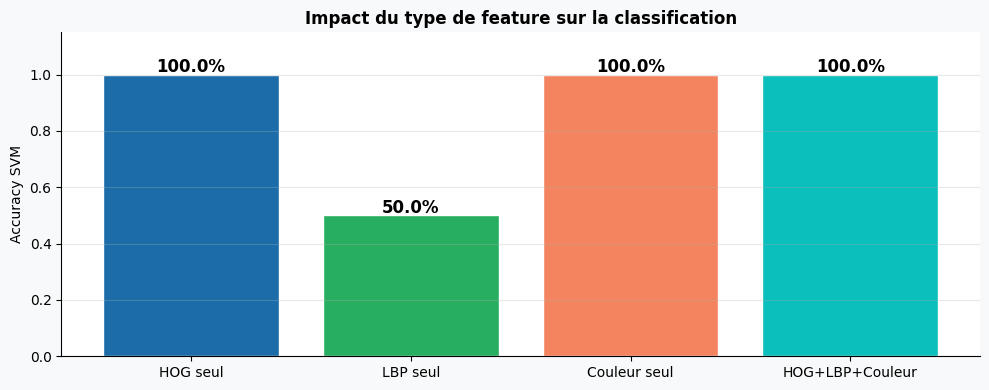

In [31]:
# ── Exercice 1.2 — À compléter ───────────────────────────────────
print("Extraction des features par type...")

# 1. Extraire chaque type de feature séparément
X_hog   = np.array([extract_hog(img)[0]     for img in dataset_imgs])
X_lbp   = np.array([extract_lbp(img)[0]     for img in dataset_imgs])
X_color = np.array([extract_color_hist(img)  for img in dataset_imgs])
X_all   = np.concatenate([X_hog, X_lbp, X_color], axis=1)

feature_sets = {"HOG seul": X_hog, "LBP seul": X_lbp,
                "Couleur seul": X_color, "HOG+LBP+Couleur": X_all}

# 2. Pour chaque jeu de features, entraîner un SVM et mesurer l'accuracy
results = {}
for name, X_feat in feature_sets.items():
    Xtr, Xte, ytr, yte = train_test_split(X_feat, y, test_size=0.25,
                                           random_state=42, stratify=y)
    sc  = StandardScaler()
    Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
    clf = SVC(kernel="rbf", C=10, gamma="scale", random_state=42)
    clf.fit(Xtr, ytr)
    results[name] = accuracy_score(yte, clf.predict(Xte))
    print(f"  {name:<25} -> {results[name]:.1%}")

# 3. Visualiser en barplot
fig, ax = plt.subplots(figsize=(10, 4))
colors = [BLUE, GREEN, ORANGE, TEAL]
bars = ax.bar(results.keys(), results.values(), color=colors, edgecolor="white")
for bar, val in zip(bars, results.values()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
            f"{val:.1%}", ha="center", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.15); ax.set_ylabel("Accuracy SVM"); ax.grid(axis="y", alpha=0.3)
ax.set_title("Impact du type de feature sur la classification")
plt.tight_layout(); plt.show()



---
### 🏋️ Exercice 1.3 ⭐ — CNN avec PyTorch (Transfer Learning)

**Objectif :** Utiliser ResNet-18 pré-entraîné comme **extracteur de features** (feature extractor), puis entraîner un classifieur SVM sur ces features profondes. Comparer avec HOG.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Feature extractor ResNet-18 :**
```python
import torch, torchvision.models as models, torchvision.transforms as T
resnet = models.resnet18(weights="IMAGENET1K_V1")
resnet.eval()
feature_extractor = torch.nn.Sequential(*list(resnet.children())[:-1])  # sans la couche FC
```
**Hint 2 — Extraire les features (512-dim) :**
```python
transform = T.Compose([T.Resize((224,224)), T.ToTensor(),
                       T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
with torch.no_grad():
    img_t = transform(Image.fromarray(img)).unsqueeze(0)
    feat  = feature_extractor(img_t).squeeze().numpy()   # (512,)
```
</details>


In [32]:
# ── Exercice 1.3 — PyTorch 
try:
    import torch
    import torchvision.models as models
    import torchvision.transforms as T

    print("PyTorch disponible — extraction des features ResNet-18...")

    resnet = models.resnet18(weights="IMAGENET1K_V1")
    resnet.eval()
    feature_extractor = torch.nn.Sequential(*list(resnet.children())[:-1])

    transform = T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    def extract_resnet_features(imgs):
        feats = []
        with torch.no_grad():
            for img in imgs:
                pil  = Image.fromarray(img)
                t    = transform(pil).unsqueeze(0)
                feat = feature_extractor(t).squeeze().numpy()
                feats.append(feat)
        return np.array(feats)

    X_resnet = extract_resnet_features(dataset_imgs)
    Xtr, Xte, ytr, yte = train_test_split(X_resnet, y, test_size=0.25,
                                           random_state=42, stratify=y)
    sc  = StandardScaler()
    Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
    clf_resnet = SVC(kernel="rbf", C=10, gamma="scale", random_state=42)
    clf_resnet.fit(Xtr, ytr)
    acc_resnet = accuracy_score(yte, clf_resnet.predict(Xte))
    print(f"Features ResNet-18 + SVM : {acc_resnet:.1%}")
    print(f"Comparaison HOG + SVM    : {acc_svm:.1%}")

except ImportError:
    print("PyTorch non disponible dans cet environnement.")
    print("Installez avec : pip install torch torchvision")
    print("Les features HOG+SVM suffisent pour la suite du TP.")


PyTorch disponible — extraction des features ResNet-18...
Features ResNet-18 + SVM : 100.0%
Comparaison HOG + SVM    : 100.0%



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #27AE60;">
  <h1 style="color:#27AE60;margin:0;font-size:1.65em;">🎯 Module 2 — Détection d'objets</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Sliding window · IoU · NMS · Anchor boxes · YOLO API</p>
</div>



### 📖 Rappel théorique

La **détection** localise et classifie N objets dans une image :

$$f(I) \rightarrow \{(b_i, c_i, s_i)\}_{i=1}^{N} \quad b_i = (x, y, w, h), \; c_i \in \{0\ldots C\}, \; s_i \in [0,1]$$

#### Approche classique : Sliding Window

```
Pour chaque position (x,y) et chaque taille de fenêtre :
    1. Extraire la région
    2. Classifier avec un SVM
    3. Si score > seuil → candidat boîte
→ Appliquer NMS pour dédoublonner
```

#### IoU — Intersection over Union

$$IoU(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|} \in [0, 1]$$

- $IoU \geq 0.5$ → Vrai Positif (PASCAL VOC)
- $IoU \geq 0.5 : 0.95$ → mAP COCO (10 seuils)

#### NMS — Non-Maximum Suppression

1. Trier les boîtes par score décroissant
2. Garder la boîte de score max
3. Supprimer les boîtes avec IoU > seuil (typiquement 0.5)
4. Répéter jusqu'à épuisement

> 💡 Les CNN modernes (YOLO, DETR) n'utilisent plus de sliding window — ils prédisent directement toutes les boîtes en **un seul passage** dans le réseau.


### 🔬 Démonstration 2.1 — IoU et NMS implémentés depuis zéro

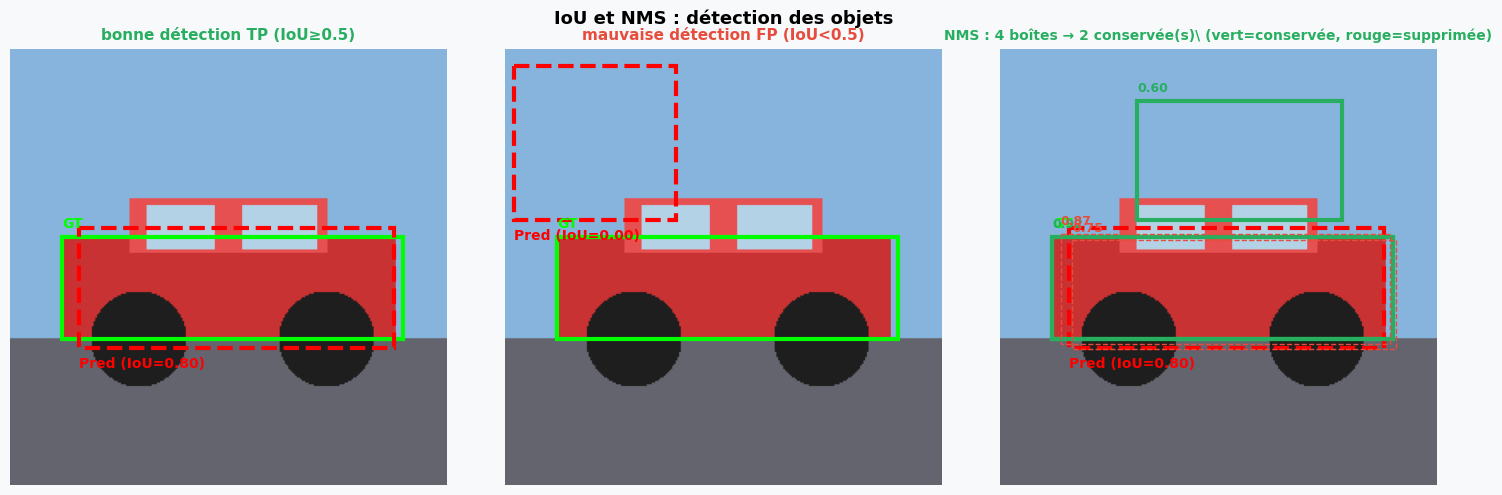

In [33]:
# ── Représentation des boîtes : (x_min, y_min, x_max, y_max) ─────

def compute_iou(box_a, box_b):
    "Calcule IoU entre deux boîtes (x1,y1,x2,y2)"
    # Intersection
    ix1 = max(box_a[0], box_b[0])
    iy1 = max(box_a[1], box_b[1])
    ix2 = min(box_a[2], box_b[2])
    iy2 = min(box_a[3], box_b[3])
    inter_w = max(0, ix2 - ix1)
    inter_h = max(0, iy2 - iy1)
    inter   = inter_w * inter_h
    # Union
    area_a  = (box_a[2]-box_a[0]) * (box_a[3]-box_a[1])
    area_b  = (box_b[2]-box_b[0]) * (box_b[3]-box_b[1])
    union   = area_a + area_b - inter
    return inter / (union + 1e-8)

def nms(boxes, scores, iou_threshold=0.5):
    # Non-Maximum Suppression.
    # boxes  : liste de (x1,y1,x2,y2)
    # scores : liste de scores de confiance
    # Retourne : indices des boîtes conservées
    if len(boxes) == 0:
        return []
    boxes  = np.array(boxes, dtype=np.float32)
    scores = np.array(scores, dtype=np.float32)
    # Trier par score décroissant
    order  = scores.argsort()[::-1]
    kept   = []
    while len(order) > 0:
        i = order[0]
        kept.append(i)
        if len(order) == 1:
            break
        # Calculer IoU avec les boîtes restantes
        ious = np.array([compute_iou(boxes[i], boxes[j]) for j in order[1:]])
        # Garder celles avec IoU < seuil
        order = order[1:][ious < iou_threshold]
    return kept

# ── Visualisation IoU ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
img_demo  = SCENES[1].copy()  # voiture

# Cas 1 : bonne détection (IoU élevé)
gt   = (30, 110, 230, 170)
pred_good = (40, 105, 225, 175)
pred_bad  = (5,  10,  100, 100)

for ax, pred, title_suffix in zip(
        axes,
        [pred_good, pred_bad, pred_good],
        ["bonne détection", "mauvaise détection", "après NMS"]):

    ax.imshow(img_demo)
    iou = compute_iou(gt, pred)

    # GT (vert)
    rect_gt = patches.Rectangle(
        (gt[0],gt[1]), gt[2]-gt[0], gt[3]-gt[1],
        linewidth=3, edgecolor="lime", facecolor="none")
    ax.add_patch(rect_gt)
    ax.text(gt[0], gt[1]-5, "GT", color="lime", fontsize=10, fontweight="bold")

    # Prédiction (rouge)
    rect_p = patches.Rectangle(
        (pred[0],pred[1]), pred[2]-pred[0], pred[3]-pred[1],
        linewidth=3, edgecolor="red", facecolor="none", linestyle="--")
    ax.add_patch(rect_p)
    ax.text(pred[0], pred[3]+12, f"Pred (IoU={iou:.2f})",
            color="red", fontsize=10, fontweight="bold")

    col = GREEN if iou >= 0.5 else RED
    verdict = "TP (IoU≥0.5)" if iou >= 0.5 else "FP (IoU<0.5)"
    ax.set_title(str(title_suffix) + " " + str(verdict) + "", fontsize=11,
                 fontweight="bold", color=col)
    ax.axis("off")

# Cas 3 : plusieurs boîtes avant/après NMS
ax = axes[2]
ax.imshow(img_demo)
multi_boxes  = [gt, (35,108,228,173), (42,112,232,176), (80,30,200,100)]
multi_scores = [0.92, 0.87, 0.75, 0.60]
kept_idx     = nms(multi_boxes, multi_scores, iou_threshold=0.5)
for i, (box, score) in enumerate(zip(multi_boxes, multi_scores)):
    color = GREEN if i in kept_idx else RED
    lw    = 3 if i in kept_idx else 1
    ls    = "-" if i in kept_idx else "--"
    r = patches.Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],
                           linewidth=lw, edgecolor=color, facecolor="none", linestyle=ls)
    ax.add_patch(r)
    ax.text(box[0], box[1]-5, f"{score:.2f}", color=color, fontsize=9, fontweight="bold")
ax.set_title(f"NMS : {len(multi_boxes)} boîtes → {len(kept_idx)} conservée(s)\ "
             f"(vert=conservée, rouge=supprimée)", fontsize=10)
ax.axis("off")
plt.suptitle("IoU et NMS : détection des objets", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


### 🔬 Démonstration 2.2 — Sliding Window avec HOG-SVM

Sliding window en cours (patience ~30s)...
Candidats avant NMS : 0
Candidats après NMS : 0


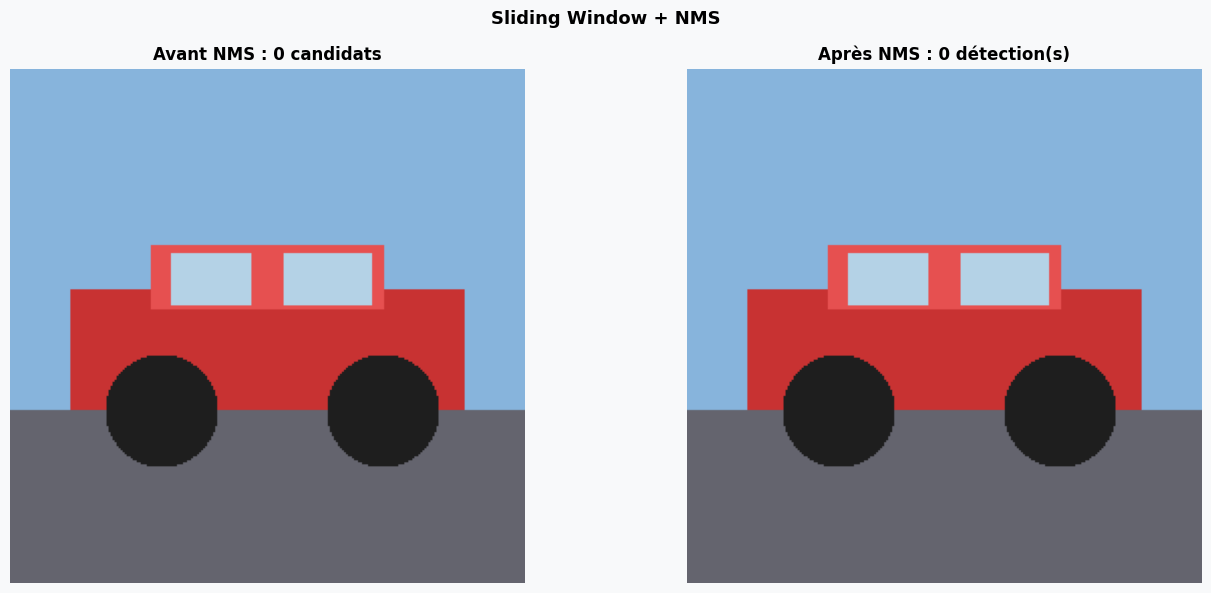

In [34]:
# ── Sliding Window Detector ───────────────────────────────────────
def sliding_window_detect(img, classifier, scaler_obj,
                          win_sizes=[(80,80),(100,60),(60,100)],
                          stride=20, threshold=0.6, target_class=1):
    # Détecteur par fenêtre glissante.
    # - Glisse des fenetres de tailles variees sur l image
    # - Classifie chaque region avec le SVM entraine
    # - Retourne boites candidates + scores
    H_img, W_img = img.shape[:2]
    candidates, candidate_scores = [], []

    for (win_h, win_w) in win_sizes:
        for y in range(0, H_img - win_h, stride):
            for x in range(0, W_img - win_w, stride):
                # Extraire la région
                region = img[y:y+win_h, x:x+win_w]
                region_resized = cv2.resize(region, (H, W))

                # Extraire les features
                feat = np.concatenate([
                    extract_hog(region_resized)[0],
                    extract_lbp(region_resized)[0],
                    extract_color_hist(region_resized)
                ]).reshape(1, -1)
                feat = scaler_obj.transform(feat)

                # Prédire
                proba = classifier.predict_proba(feat)[0]
                if proba[target_class] > threshold:
                    candidates.append((x, y, x+win_w, y+win_h))
                    candidate_scores.append(proba[target_class])

    return candidates, candidate_scores

# ── Test sur la voiture ───────────────────────────────────────────
print("Sliding window en cours (patience ~30s)...")
test_img   = SCENES[1].copy()   # voiture = classe 1
cands, scores = sliding_window_detect(
    test_img, svm, scaler,
    win_sizes=[(180, 220)],      # une seule taille pour la démo
    stride=30, threshold=0.55, target_class=1
)

print(f"Candidats avant NMS : {len(cands)}")
kept = nms(cands, scores, iou_threshold=0.45) if cands else []
print(f"Candidats après NMS : {len(kept)}")

# ── Visualisation ─────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.imshow(test_img)
for i, (box, sc) in enumerate(zip(cands, scores)):
    col = GREEN if i in kept else RED
    lw  = 3 if i in kept else 0.8
    r = patches.Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],
                           linewidth=lw, edgecolor=col, facecolor="none", linestyle="--" if i not in kept else "-")
    ax1.add_patch(r)
    if i in kept:
        ax1.text(box[0], box[1]-5, f"{sc:.2f}", color=GREEN, fontsize=9, fontweight="bold")
ax1.set_title(f"Avant NMS : {len(cands)} candidats", fontsize=12); ax1.axis("off")

ax2.imshow(test_img)
for i in kept:
    box, sc = cands[i], scores[i]
    r = patches.Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],
                           linewidth=3, edgecolor=GREEN, facecolor="none")
    ax2.add_patch(r)
    bg = patches.FancyBboxPatch((box[0], box[1]-22), 90, 20,
                                boxstyle="round,pad=2", facecolor=GREEN, edgecolor="none", alpha=0.8)
    ax2.add_patch(bg)
    ax2.text(box[0]+5, box[1]-7, f"Voiture {sc:.2f}", color="white", fontsize=9, fontweight="bold")
ax2.set_title(f"Après NMS : {len(kept)} détection(s)", fontsize=12); ax2.axis("off")
plt.suptitle("Sliding Window + NMS", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()



---
### 🏋️ Exercice 2.1 — Implémenter compute_iou_batch et calculer la mAP@0.5

**Objectif :** Calculer l'IoU vectorisé entre **toutes les paires** de boîtes (N prédictions vs M ground truths), puis calculer la mAP@0.5 sur un jeu de test simulé.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — IoU vectorisé (N boîtes prédites vs M GT) :**
```python
def compute_iou_matrix(pred_boxes, gt_boxes):
    # pred_boxes : (N, 4), gt_boxes : (M, 4)
    N, M = len(pred_boxes), len(gt_boxes)
    iou_mat = np.zeros((N, M))
    for i, pb in enumerate(pred_boxes):
        for j, gb in enumerate(gt_boxes):
            iou_mat[i, j] = compute_iou(pb, gb)
    return iou_mat   # (N, M)
```
**Hint 2 — Précision et Rappel à partir de la matrice IoU :**
```python
# Pour chaque prédiction (triée par score) :
# TP si max IoU avec un GT non encore assigné >= 0.5
```
**Hint 3 — AP = aire sous la courbe P-R :**
```python
ap = np.trapezoid(precisions[::-1], recalls[::-1])
```
</details>


Matrice IoU (N prédictions × M GT) :
[[0.935 0.046]
 [0.891 0.053]
 [0.009 0.   ]
 [0.047 0.886]]
AP@0.5 : 0.000


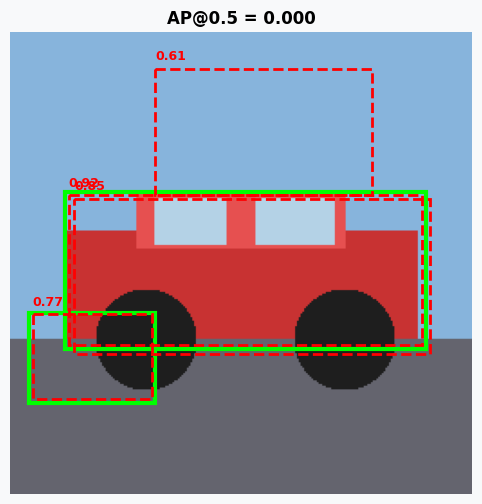

In [35]:
# ── Exercice 2.1 —

def compute_iou_matrix(pred_boxes, gt_boxes):
    "IoU entre toutes les paires (N prédictions × M GT)"
    N, M = len(pred_boxes), len(gt_boxes)
    iou_mat = np.zeros((N, M))
    for i, pb in enumerate(pred_boxes):
        for j, gb in enumerate(gt_boxes):
            iou_mat[i, j] = compute_iou(pb, gb)
    return iou_mat


def compute_ap(pred_boxes, pred_scores, gt_boxes, iou_thresh=0.5):
    # Calcule l'Average Precision pour une classe.
    if len(pred_boxes) == 0:
        return 0.0
    if len(gt_boxes) == 0:
        return 0.0

    # 1. Trier prédictions par score décroissant
    order = np.argsort(pred_scores)[::-1]
    pred_boxes  = np.array(pred_boxes)[order]
    pred_scores = np.array(pred_scores)[order]

    iou_mat   = compute_iou_matrix(pred_boxes, gt_boxes)
    gt_matched = np.zeros(len(gt_boxes), dtype=bool)

    tps, fps = [], []
    for i in range(len(pred_boxes)):
        if iou_mat.max() > 0:
            best_gt = iou_mat[i].argmax()
            if iou_mat[i, best_gt] >= iou_thresh and not gt_matched[best_gt]:
                tps.append(1); fps.append(0)
                gt_matched[best_gt] = True
            else:
                tps.append(0); fps.append(1)
        else:
            fps.append(1); tps.append(0)

    tps_cum = np.cumsum(tps)
    fps_cum = np.cumsum(fps)
    recalls    = tps_cum / (len(gt_boxes) + 1e-8)
    precisions = tps_cum / (tps_cum + fps_cum + 1e-8)

    # AP = aire sous la courbe P-R
    ap = np.trapezoid(precisions[::-1], recalls[::-1])
    return max(0.0, ap)


# ── Simulation d'un scénario de détection ─────────────────────────
gt_boxes_demo = np.array([
    [30, 88, 230, 175],    # voiture principale
    [10, 155, 80, 205],    # roue gauche (proche)
])

pred_demo = np.array([
    [32, 90, 228, 173],   # bonne détection
    [35, 92, 232, 178],   # doublon
    [80, 20, 200, 90],    # faux positif
    [12, 156, 78, 203],   # bonne roue
])
scores_demo = [0.92, 0.85, 0.61, 0.77]

# Calculer IoU matrix
iou_matrix = compute_iou_matrix(pred_demo, gt_boxes_demo)
print("Matrice IoU (N prédictions × M GT) :")
print(iou_matrix.round(3))

# Calculer AP@0.5
ap = compute_ap(pred_demo, scores_demo, gt_boxes_demo, iou_thresh=0.5)
print(f"AP@0.5 : {ap:.3f}")

# Visualiser les boîtes
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(SCENES[1])
for box in gt_boxes_demo:
    r = patches.Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],
                           linewidth=3, edgecolor="lime", facecolor="none", label="GT")
    ax.add_patch(r)
for box, sc in zip(pred_demo, scores_demo):
    r = patches.Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],
                           linewidth=2, edgecolor="red", facecolor="none", linestyle="--")
    ax.add_patch(r)
    ax.text(box[0], box[1]-5, f"{sc:.2f}", color="red", fontsize=9, fontweight="bold")
ax.set_title(f"AP@0.5 = {ap:.3f}"); ax.axis("off"); plt.show()



<details>
<summary>✅ <strong>Correction</strong></summary>

```python
def compute_iou_matrix(pred_boxes, gt_boxes):
    N, M = len(pred_boxes), len(gt_boxes)
    iou_mat = np.zeros((N, M))
    for i, pb in enumerate(pred_boxes):
        for j, gb in enumerate(gt_boxes):
            iou_mat[i, j] = compute_iou(pb, gb)
    return iou_mat

# Dans compute_ap :
ap = np.trapezoid(precisions[::-1], recalls[::-1])
return max(0.0, ap)
```
</details>



---
### 🏋️ Exercice 2.2 — Détection par template matching (corrélation croisée)

**Objectif :** Implémenter un détecteur simple par **template matching** (cv2.matchTemplate) pour localiser la voiture dans une scène modifiée, puis convertir la carte de corrélation en boîtes détectées.

> Le template matching calcule la corrélation entre un patron (template) et chaque région de l'image :
> $$R(x,y) = \sum_{x',y'} T(x',y') \cdot I(x+x', y+y')$$

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Template matching avec OpenCV :**
```python
template = gray_scene[88:175, 30:230]   # zone voiture en gris
result   = cv2.matchTemplate(gray_full, template, cv2.TM_CCOEFF_NORMED)
# result : carte 2D de corrélation, valeurs dans [-1, 1]
```
**Hint 2 — Localiser le maximum :**
```python
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)
top_left     = max_loc
bottom_right = (top_left[0]+template.shape[1], top_left[1]+template.shape[0])
```
**Hint 3 — Multi-scale matching :** répéter avec l'image redimensionnée à différentes échelles pour gérer les changements de taille.
</details>


Corrélation max : 0.970  position : (30, 88)


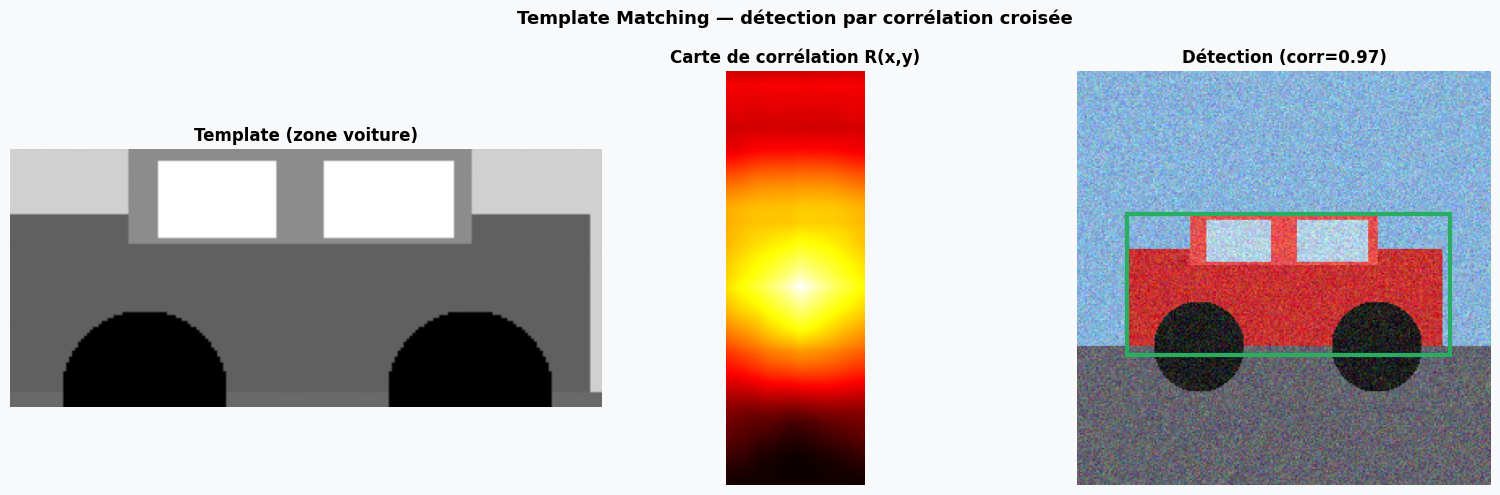

In [36]:
# ── Exercice 2.2 —

# Préparer la scène et le template
car_scene    = SCENES[1].copy()
gray_scene   = cv2.cvtColor(car_scene, cv2.COLOR_RGB2GRAY)

# Template : zone de la carrosserie de la voiture
template     = gray_scene[88:175, 30:230]   # y1:y2, x1:x2

# Créer une version modifiée de la scène (décalée / bruit)
test_full    = car_scene.copy()
# Ajouter du bruit
noise        = np.random.randn(*test_full.shape) * 20
test_full    = np.clip(test_full.astype(np.float32)+noise, 0, 255).astype(np.uint8)
gray_full    = cv2.cvtColor(test_full, cv2.COLOR_RGB2GRAY)

# 1. Appliquer cv2.matchTemplate
result = cv2.matchTemplate(gray_full, template, cv2.TM_CCOEFF_NORMED)

# 2. Trouver le maximum de corrélation
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)
top_left     = max_loc
h_t, w_t     = template.shape
bottom_right = (top_left[0]+w_t, top_left[1]+h_t)
print(f"Corrélation max : {max_val:.3f}  position : {max_loc}")

# 3. Afficher la carte de corrélation + la détection
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(template, cmap="gray")
axes[0].set_title("Template (zone voiture)"); axes[0].axis("off")
axes[1].imshow(result, cmap="hot")
axes[1].set_title("Carte de corrélation R(x,y)"); axes[1].axis("off")
axes[2].imshow(test_full)
rect = patches.Rectangle(top_left, w_t, h_t, linewidth=3, edgecolor=GREEN, facecolor="none")
axes[2].add_patch(rect)
axes[2].set_title(f"Détection (corr={max_val:.2f})"); axes[2].axis("off")
plt.suptitle("Template Matching — détection par corrélation croisée", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()



---
### 🏋️ Exercice 2.3 ⭐ — Détection avec YOLO via API (torchvision)

**Objectif :** Utiliser `torchvision.ops.box_iou` et comprendre le format de sortie d'un détecteur moderne.

<details>
<summary>💡 <strong>Hints</strong></summary>

```python
import torch
from torchvision.ops import box_iou, nms as torch_nms

# box_iou attend des tensors (N,4) et (M,4)
boxes_t = torch.tensor(pred_demo, dtype=torch.float32)
gt_t    = torch.tensor(gt_boxes_demo, dtype=torch.float32)
iou_mat = box_iou(boxes_t, gt_t)   # (N, M)

# NMS torchvision
kept_idx = torch_nms(boxes_t, torch.tensor(scores_demo), iou_threshold=0.5)
```
</details>


Matrice IoU (torchvision) :
[[0.935 0.046]
 [0.891 0.053]
 [0.009 0.   ]
 [0.047 0.886]]
NMS torchvision : indices conservés = [0, 3, 2]


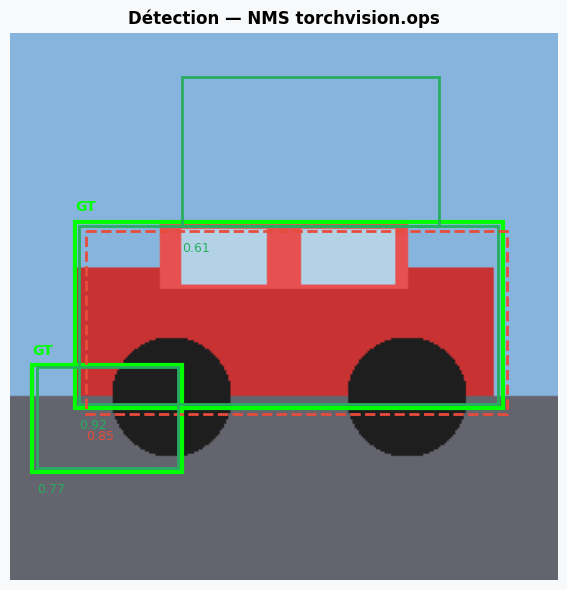

In [37]:
# ── Exercice 2.3 —
try:
    import torch
    from torchvision.ops import box_iou, nms as torch_nms

    boxes_t  = torch.tensor(pred_demo, dtype=torch.float32)
    gt_t     = torch.tensor(gt_boxes_demo, dtype=torch.float32)
    scores_t = torch.tensor(scores_demo, dtype=torch.float32)

    # IoU matrix
    iou_mat_torch = box_iou(boxes_t, gt_t)
    print("Matrice IoU (torchvision) :")
    print(iou_mat_torch.numpy().round(3))

    # NMS
    kept_torch = torch_nms(boxes_t, scores_t, iou_threshold=0.5)
    print(f"NMS torchvision : indices conservés = {kept_torch.tolist()}")

    # Visualiser
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(SCENES[1])
    for box in gt_boxes_demo:
        r = patches.Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],
                               linewidth=3, edgecolor="lime", facecolor="none")
        ax.add_patch(r)
        ax.text(box[0], box[1]-5, "GT", color="lime", fontsize=10, fontweight="bold")
    for i, (box, sc) in enumerate(zip(pred_demo, scores_demo)):
        color = GREEN if i in kept_torch.tolist() else RED
        r = patches.Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],
                               linewidth=2, edgecolor=color, facecolor="none",
                               linestyle="-" if i in kept_torch.tolist() else "--")
        ax.add_patch(r)
        ax.text(box[0], box[3]+12, f"{sc:.2f}", color=color, fontsize=9)
    ax.set_title("Détection — NMS torchvision.ops"); ax.axis("off")
    plt.tight_layout(); plt.show()

except (ImportError, RuntimeError, Exception) as e:
    print(f"PyTorch non disponible : {e}")
    print("Implémentation NumPy ci-dessus suffisante pour le TP.")



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #8E44AD;">
  <h1 style="color:#8E44AD;margin:0;font-size:1.65em;">🗺️ Module 3 — Segmentation d'images</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Seuillage · K-Means · GrabCut · SLIC · Watershed · Masques · mIoU</p>
</div>



### 📖 Rappel théorique

La **segmentation** attribue un label à **chaque pixel** :

$$f(I) \rightarrow M \quad \text{où} \quad M[h,w] \in \{0, 1, \ldots, C-1\} \quad \forall (h,w)$$

#### Niveaux de segmentation

| Type | Sortie | Algorithmes |
|------|--------|-------------|
| **Binaire** (fond/objet) | Masque 0/1 | Otsu, GrabCut |
| **Sémantique** | Label par pixel (C classes) | U-Net, SegFormer, FCN |
| **Instances** | Masque par objet individuel | Mask R-CNN, SAM |
| **Panoptique** | Sémantique + instances | Panoptic FPN |

#### Méthode Otsu (seuillage automatique)

Minimise la variance intra-classe entre deux groupes (fond / objet) :
$$\sigma^2_w(t) = w_0(t)\sigma_0^2(t) + w_1(t)\sigma_1^2(t)$$
$$t^* = \arg\min_t \sigma^2_w(t)$$

#### Dice Score (métrique de segmentation)

$$\text{Dice} = \frac{2|P \cap G|}{|P| + |G|} = \frac{2 \cdot TP}{2TP + FP + FN} \in [0, 1]$$

#### mIoU — mean Intersection over Union

$$\text{mIoU} = \frac{1}{C} \sum_{c=0}^{C-1} \frac{TP_c}{TP_c + FP_c + FN_c}$$


### 🔬 Démonstration 3.1 — Seuillage : global, Otsu, adaptatif

Seuil Otsu automatique : 130


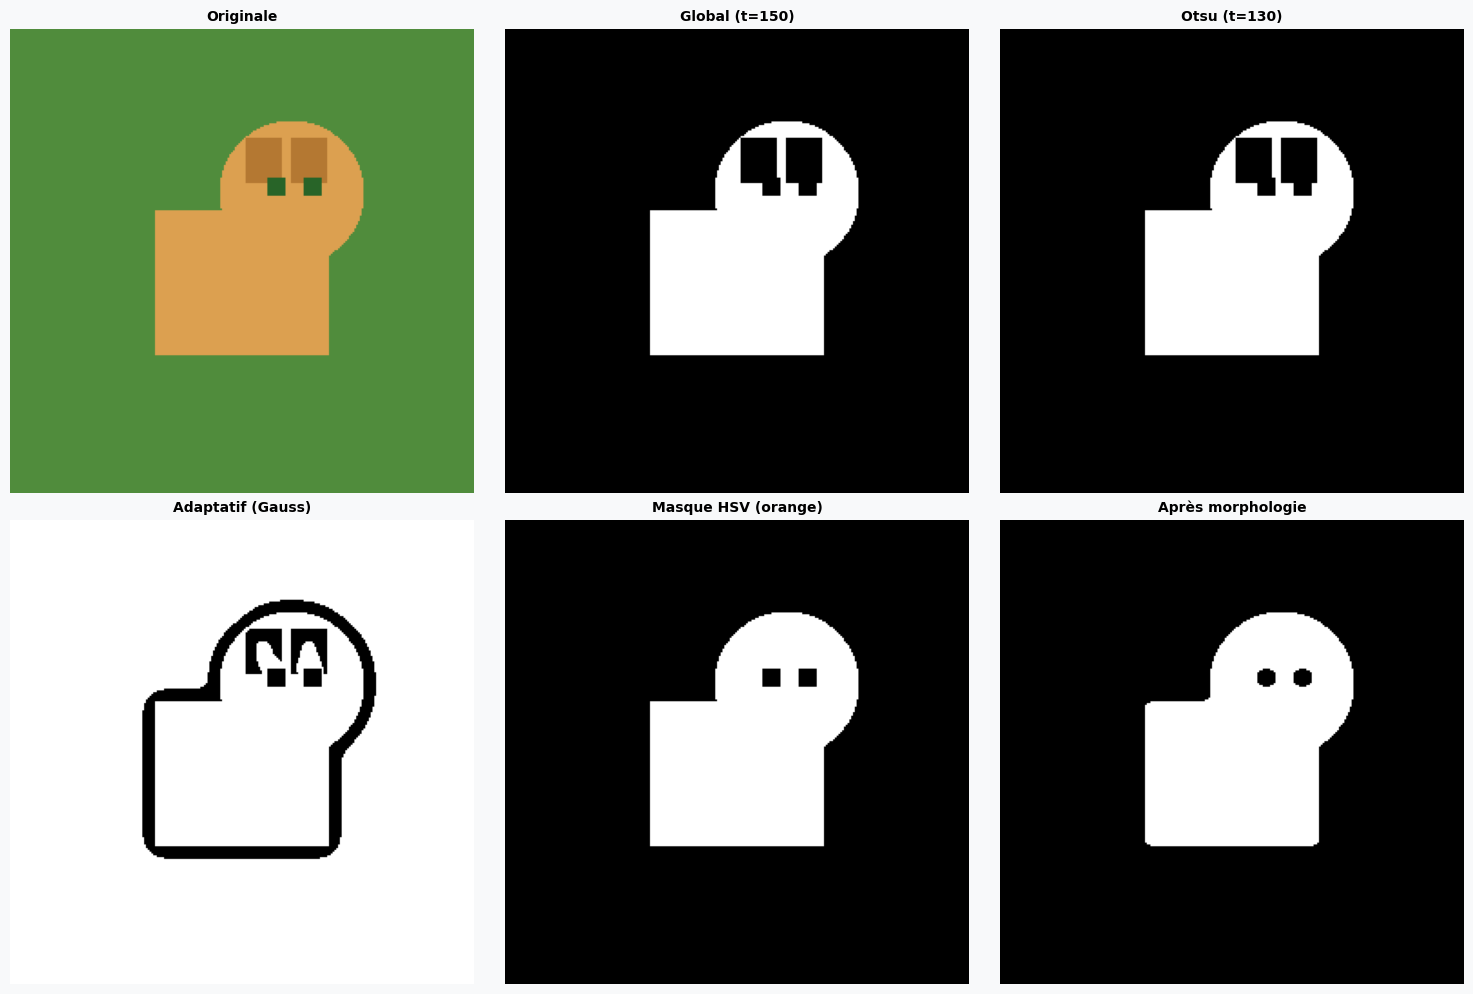

In [38]:
# ── Image de test ─────────────────────────────────────────────────
img_seg = SCENES[0].copy()   # chat
gray    = cv2.cvtColor(img_seg, cv2.COLOR_RGB2GRAY)

# ── Seuillage global (manuel) ─────────────────────────────────────
thresh_manual = 150
mask_manual   = (gray > thresh_manual).astype(np.uint8) * 255

# ── Otsu (automatique) ────────────────────────────────────────────
otsu_val, mask_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Seuil Otsu automatique : {otsu_val:.0f}")

# ── Adaptatif (Gaussian) ──────────────────────────────────────────
mask_adapt = cv2.adaptiveThreshold(gray, 255,
                                    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 31, 5)

# ── Seuillage HSV (couleur spécifique) ───────────────────────────
hsv = cv2.cvtColor(img_seg, cv2.COLOR_RGB2HSV)
# Sélectionner teinte orange (chat)
lower_orange = np.array([8,  80,  80])
upper_orange = np.array([30, 255, 255])
mask_hsv     = cv2.inRange(hsv, lower_orange, upper_orange)

# ── Post-traitement morphologique ─────────────────────────────────
kernel        = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask_cleaned  = cv2.morphologyEx(mask_hsv, cv2.MORPH_CLOSE, kernel)
mask_cleaned  = cv2.morphologyEx(mask_cleaned, cv2.MORPH_OPEN, kernel)

show_grid(
    [img_seg, mask_manual, mask_otsu, mask_adapt, mask_hsv, mask_cleaned],
    ["Originale", f"Global (t={thresh_manual})", f"Otsu (t={otsu_val:.0f})",
     "Adaptatif (Gauss)", "Masque HSV (orange)", "Après morphologie"],
    ncols=3, figsize=(15, 10),
    cmaps=[None, "gray", "gray", "gray", "gray", "gray"]
)


### 🔬 Démonstration 3.2 — Segmentation par régions : K-Means, SLIC, GrabCut

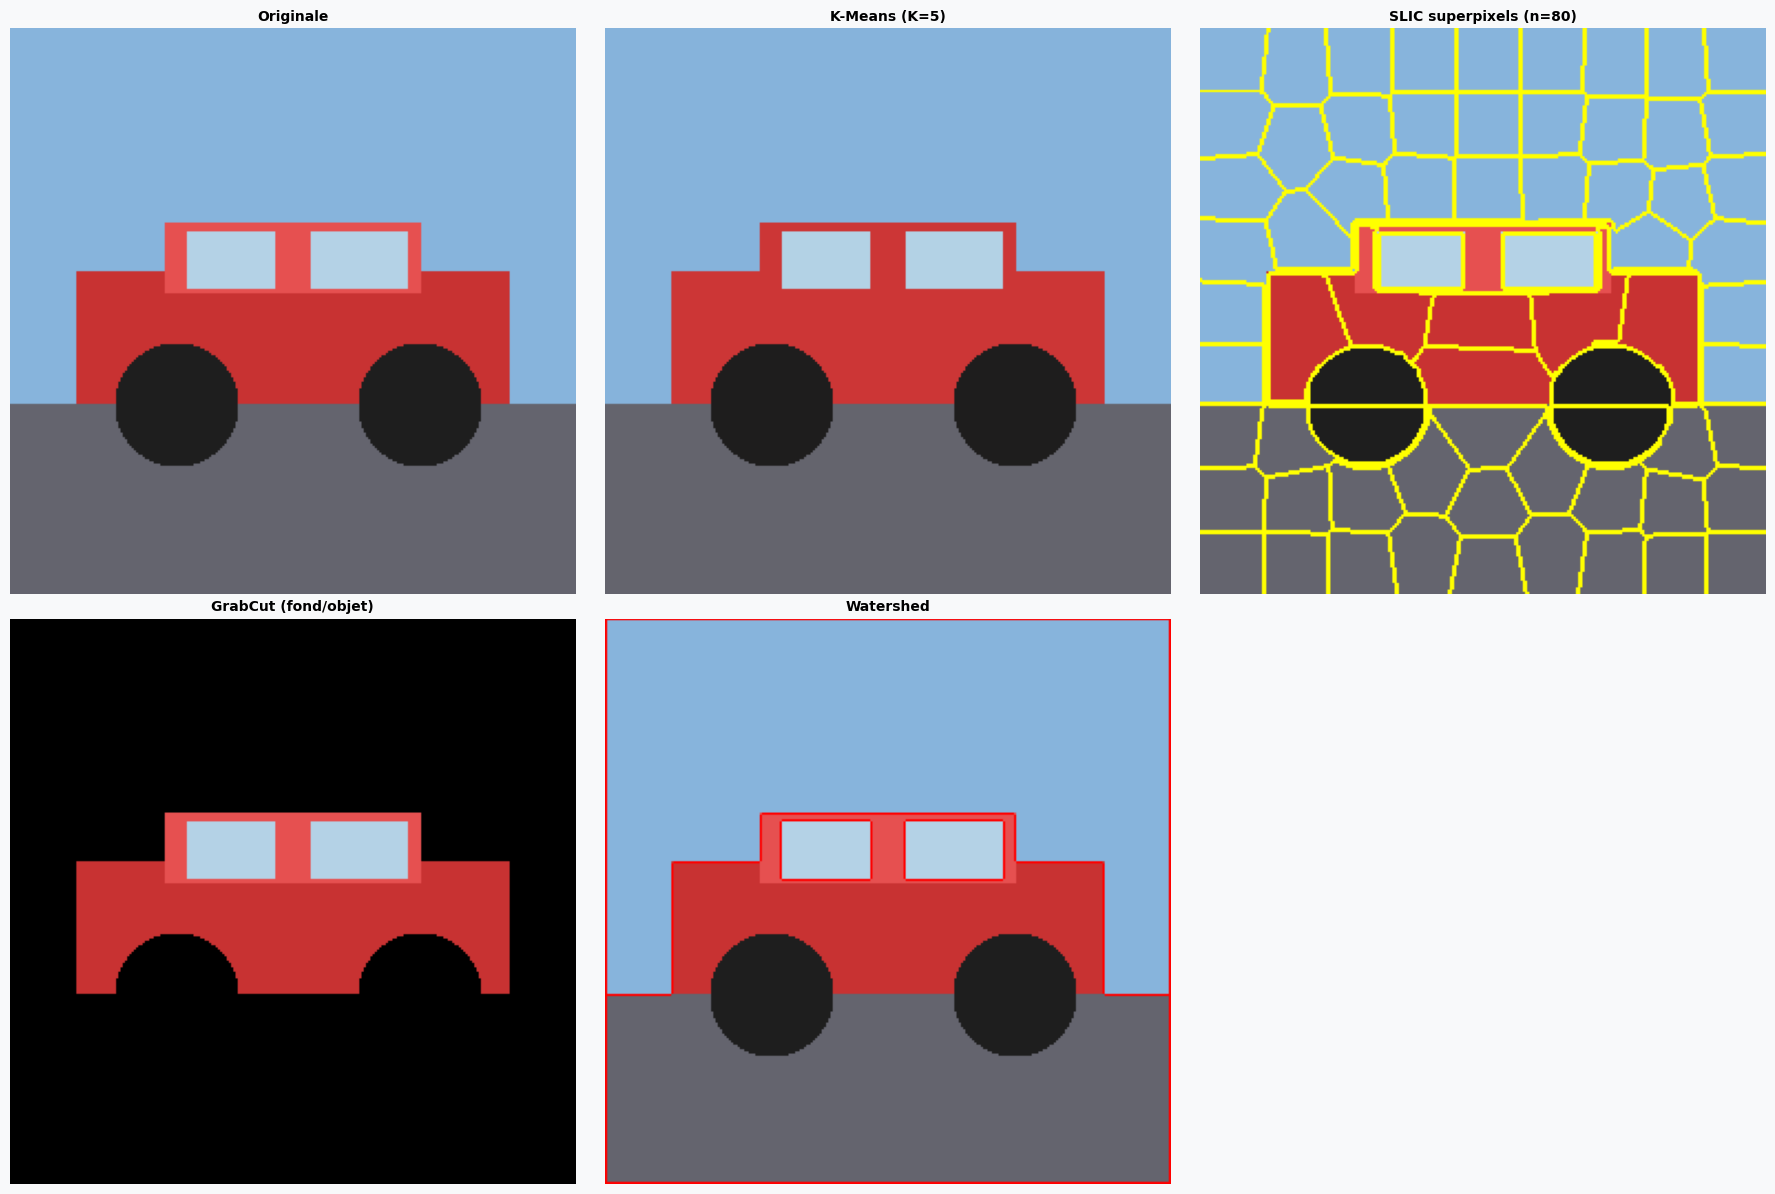

In [39]:
# ── K-Means couleur ───────────────────────────────────────────────
def kmeans_segment(img, K=4):
    "Segmentation par K-Means dans l'espace couleur"
    data = img.reshape(-1, 3).astype(np.float32)
    km   = KMeans(n_clusters=K, n_init=5, random_state=42, max_iter=50)
    km.fit(data)
    labels = km.labels_.reshape(img.shape[:2])
    # Reconstruire l'image avec la couleur moyenne de chaque cluster
    colors = km.cluster_centers_.astype(np.uint8)
    seg_img = colors[labels]
    return labels, seg_img

# ── SLIC (superpixels) ────────────────────────────────────────────
def slic_segment(img, n_segments=100, compactness=10):
    img_float = img.astype(np.float64) / 255.0
    segments  = slic(img_float, n_segments=n_segments,
                     compactness=compactness, sigma=1, start_label=0)
    boundaries = mark_boundaries(img_float, segments)
    return segments, boundaries

# ── GrabCut ───────────────────────────────────────────────────────
def grabcut_segment(img, rect=None):
    "GrabCut avec rectangle initial autour de l'objet central"
    if rect is None:
        h, w = img.shape[:2]
        rect = (w//8, h//8, 3*w//4, 3*h//4)  # rectangle central

    # GrabCut attend BGR
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    mask_gc  = np.zeros(img.shape[:2], np.uint8)
    bgd_model = np.zeros((1,65), np.float64)
    fgd_model = np.zeros((1,65), np.float64)

    cv2.grabCut(img_bgr, mask_gc, rect, bgd_model, fgd_model, 5, cv2.GC_INIT_WITH_RECT)

    # 0=BGD, 1=FGD, 2=prob_BGD, 3=prob_FGD
    fg_mask  = np.where((mask_gc==2)|(mask_gc==0), 0, 1).astype(np.uint8)
    result   = img * fg_mask[:, :, np.newaxis]
    return fg_mask, result

# ── Visualisation comparative ─────────────────────────────────────
img_demo = SCENES[1].copy()  # voiture

_, km_img        = kmeans_segment(img_demo, K=5)
_, slic_vis      = slic_segment(img_demo, n_segments=80)
fg_mask, gc_res  = grabcut_segment(img_demo, rect=(30, 88, 200, 90))

# Watershed
gray_w   = cv2.cvtColor(img_demo, cv2.COLOR_RGB2GRAY)
_, bin_w = cv2.threshold(gray_w, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
kernel_w = np.ones((3,3), np.uint8)
sure_bg  = cv2.dilate(bin_w, kernel_w, iterations=3)
dist_t   = ndi.distance_transform_edt(bin_w)
sure_fg  = (dist_t > 0.3 * dist_t.max()).astype(np.uint8) * 255
unknown  = cv2.subtract(sure_bg, sure_fg)
_, markers = cv2.connectedComponents(sure_fg)
markers += 1; markers[unknown==255] = 0
img_bgr_w = cv2.cvtColor(img_demo, cv2.COLOR_RGB2BGR)
ws        = cv2.watershed(img_bgr_w, markers)
ws_vis    = img_demo.copy()
ws_vis[ws==-1] = [255, 0, 0]  # contours en rouge

show_grid(
    [img_demo, km_img, (slic_vis*255).astype(np.uint8), gc_res, ws_vis],
    ["Originale", "K-Means (K=5)", "SLIC superpixels (n=80)",
     "GrabCut (fond/objet)", "Watershed"],
    ncols=3, figsize=(18, 12)
)



---
### 🏋️ Exercice 3.1 — Implémenter les métriques Dice et mIoU depuis zéro

**Objectif :** Calculer Dice et mIoU entre un masque prédit (K-Means) et un masque GT (seuillage HSV), pour deux classes : fond et objet.

**Formules :**
$$\text{Dice}_c = \frac{2 \cdot TP_c}{2TP_c + FP_c + FN_c} \qquad \text{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}$$
$$\text{mIoU} = \frac{1}{C} \sum_{c} IoU_c$$

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — TP, FP, FN pour la classe c :**
```python
tp = ((pred == c) & (gt == c)).sum()
fp = ((pred == c) & (gt != c)).sum()
fn = ((pred != c) & (gt == c)).sum()
```
**Hint 2 — Binariser le masque K-Means (trouver le cluster correspondant à l'objet) :**
```python
# Trouver le cluster dominant dans la zone GT
labels_km, _ = kmeans_segment(img, K=3)
# Comparer avec le masque HSV (ground truth)
best_cluster = max(range(K), key=lambda k: ((labels_km==k) & (mask_gt>0)).sum())
pred_binary  = (labels_km == best_cluster).astype(np.uint8)
```
</details>


Dice   : fond=0.991  objet=0.955  moy=0.973
IoU    : fond=0.983  objet=0.914
mIoU   : 0.949


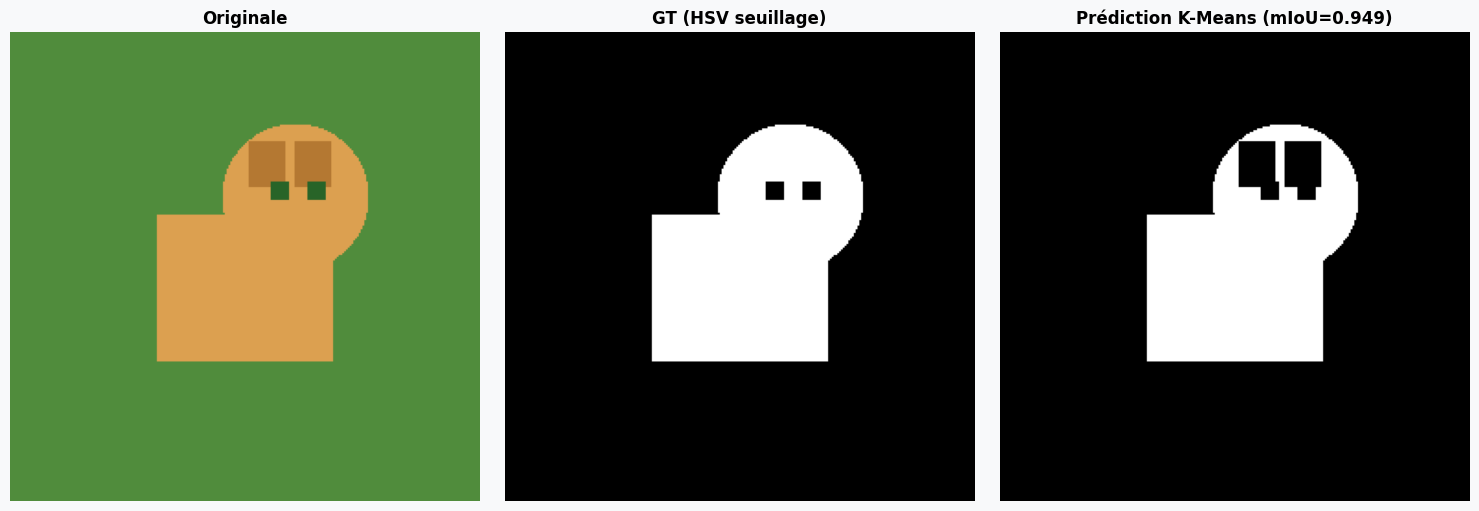

In [40]:
# ── Exercice 3.1 — By DRISS Amine

def compute_dice(pred_mask, gt_mask, n_classes=2):
    # Calcule le Dice Score pour chaque classe.
    dice_per_class = []
    for c in range(n_classes):
        tp = ((pred_mask == c) & (gt_mask == c)).sum()
        fp = ((pred_mask == c) & (gt_mask != c)).sum()
        fn = ((pred_mask != c) & (gt_mask == c)).sum()
        dice_c = 2*tp / (2*tp + fp + fn + 1e-8)
        dice_per_class.append(dice_c)
    return np.array(dice_per_class)


def compute_miou(pred_mask, gt_mask, n_classes=2):
    # Calcule le mIoU (mean Intersection over Union).
    iou_per_class = []
    for c in range(n_classes):
        tp = ((pred_mask == c) & (gt_mask == c)).sum()
        fp = ((pred_mask == c) & (gt_mask != c)).sum()
        fn = ((pred_mask != c) & (gt_mask == c)).sum()
        iou_c = tp / (tp + fp + fn + 1e-8)
        iou_per_class.append(iou_c)
    return np.array(iou_per_class), np.mean(iou_per_class)


# ── Préparer les masques ──────────────────────────────────────────
img_eval = SCENES[0].copy()

# GT : seuillage HSV (orange = chat)
hsv_eval = cv2.cvtColor(img_eval, cv2.COLOR_RGB2HSV)
gt_mask_binary = (cv2.inRange(hsv_eval, np.array([8,80,80]),
                              np.array([30,255,255])) > 0).astype(np.uint8)

# Prédiction K-Means
labels_km_eval, _ = kmeans_segment(img_eval, K=3)

# Aligner le cluster K-Means avec le masque GT
best_c = max(range(3), key=lambda k: ((labels_km_eval==k) & (gt_mask_binary==1)).sum())
pred_mask_binary = (labels_km_eval == best_c).astype(np.uint8)

# Calculer Dice et mIoU
dice = compute_dice(pred_mask_binary, gt_mask_binary, n_classes=2)
iou_per_c, miou = compute_miou(pred_mask_binary, gt_mask_binary, n_classes=2)
print("Dice   : fond=%.3f  objet=%.3f  moy=%.3f" % (dice[0], dice[1], dice.mean()))
print("IoU    : fond=%.3f  objet=%.3f" % (iou_per_c[0], iou_per_c[1]))
print("mIoU   : %.3f" % miou)

# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_eval); axes[0].set_title("Originale"); axes[0].axis("off")
axes[1].imshow(gt_mask_binary, cmap="gray")
axes[1].set_title("GT (HSV seuillage)"); axes[1].axis("off")
axes[2].imshow(pred_mask_binary, cmap="gray")
axes[2].set_title(f"Prédiction K-Means (mIoU={miou:.3f})"); axes[2].axis("off")
plt.tight_layout(); plt.show()



<details>
<summary>✅ <strong>Correction</strong></summary>

```python
def compute_dice(pred_mask, gt_mask, n_classes=2):
    dice_per_class = []
    for c in range(n_classes):
        tp = ((pred_mask == c) & (gt_mask == c)).sum()
        fp = ((pred_mask == c) & (gt_mask != c)).sum()
        fn = ((pred_mask != c) & (gt_mask == c)).sum()
        dice_c = 2*tp / (2*tp + fp + fn + 1e-8)
        dice_per_class.append(dice_c)
    return np.array(dice_per_class)

def compute_miou(pred_mask, gt_mask, n_classes=2):
    iou_per_class = []
    for c in range(n_classes):
        tp = ((pred_mask == c) & (gt_mask == c)).sum()
        fp = ((pred_mask == c) & (gt_mask != c)).sum()
        fn = ((pred_mask != c) & (gt_mask == c)).sum()
        iou_c = tp / (tp + fp + fn + 1e-8)
        iou_per_class.append(iou_c)
    return np.array(iou_per_class), np.mean(iou_per_class)
```
</details>



---
### 🏋️ Exercice 3.2 — Segmentation multi-classes par couleur HSV

**Objectif :** Implémenter une **segmentation sémantique à 4 classes** sur nos scènes synthétiques en utilisant des plages HSV pour chaque classe (ciel, sol, objet principal, bâtiment), et calculer la matrice de confusion pixel par pixel.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Plages HSV par classe :**
```python
# Classe 0 : Ciel (bleu clair)
lower_sky = np.array([95, 40, 130]); upper_sky = np.array([130, 180, 240])
# Classe 1 : Sol (vert)
lower_ground = np.array([35, 40, 40]); upper_ground = np.array([85, 255, 160])
# Classe 2 : Objet rouge (voiture/maison)
lower_obj1 = np.array([0, 80, 100]); upper_obj1 = np.array([10, 255, 255])
# Classe 3 : Objet orange (chat)
lower_obj2 = np.array([10, 80, 80]); upper_obj2 = np.array([30, 255, 255])
```
**Hint 2 — Construire le masque multi-classes :**
```python
seg_mask = np.zeros(img.shape[:2], dtype=np.uint8)   # tout = fond (classe 0)
seg_mask[cv2.inRange(hsv, lower_sky, upper_sky) > 0]    = 1
seg_mask[cv2.inRange(hsv, lower_ground, upper_ground) > 0] = 2
# ...
```
**Hint 3 — Matrice de confusion pixel :**
```python
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(gt_flat, pred_flat, labels=range(n_classes))
```
</details>


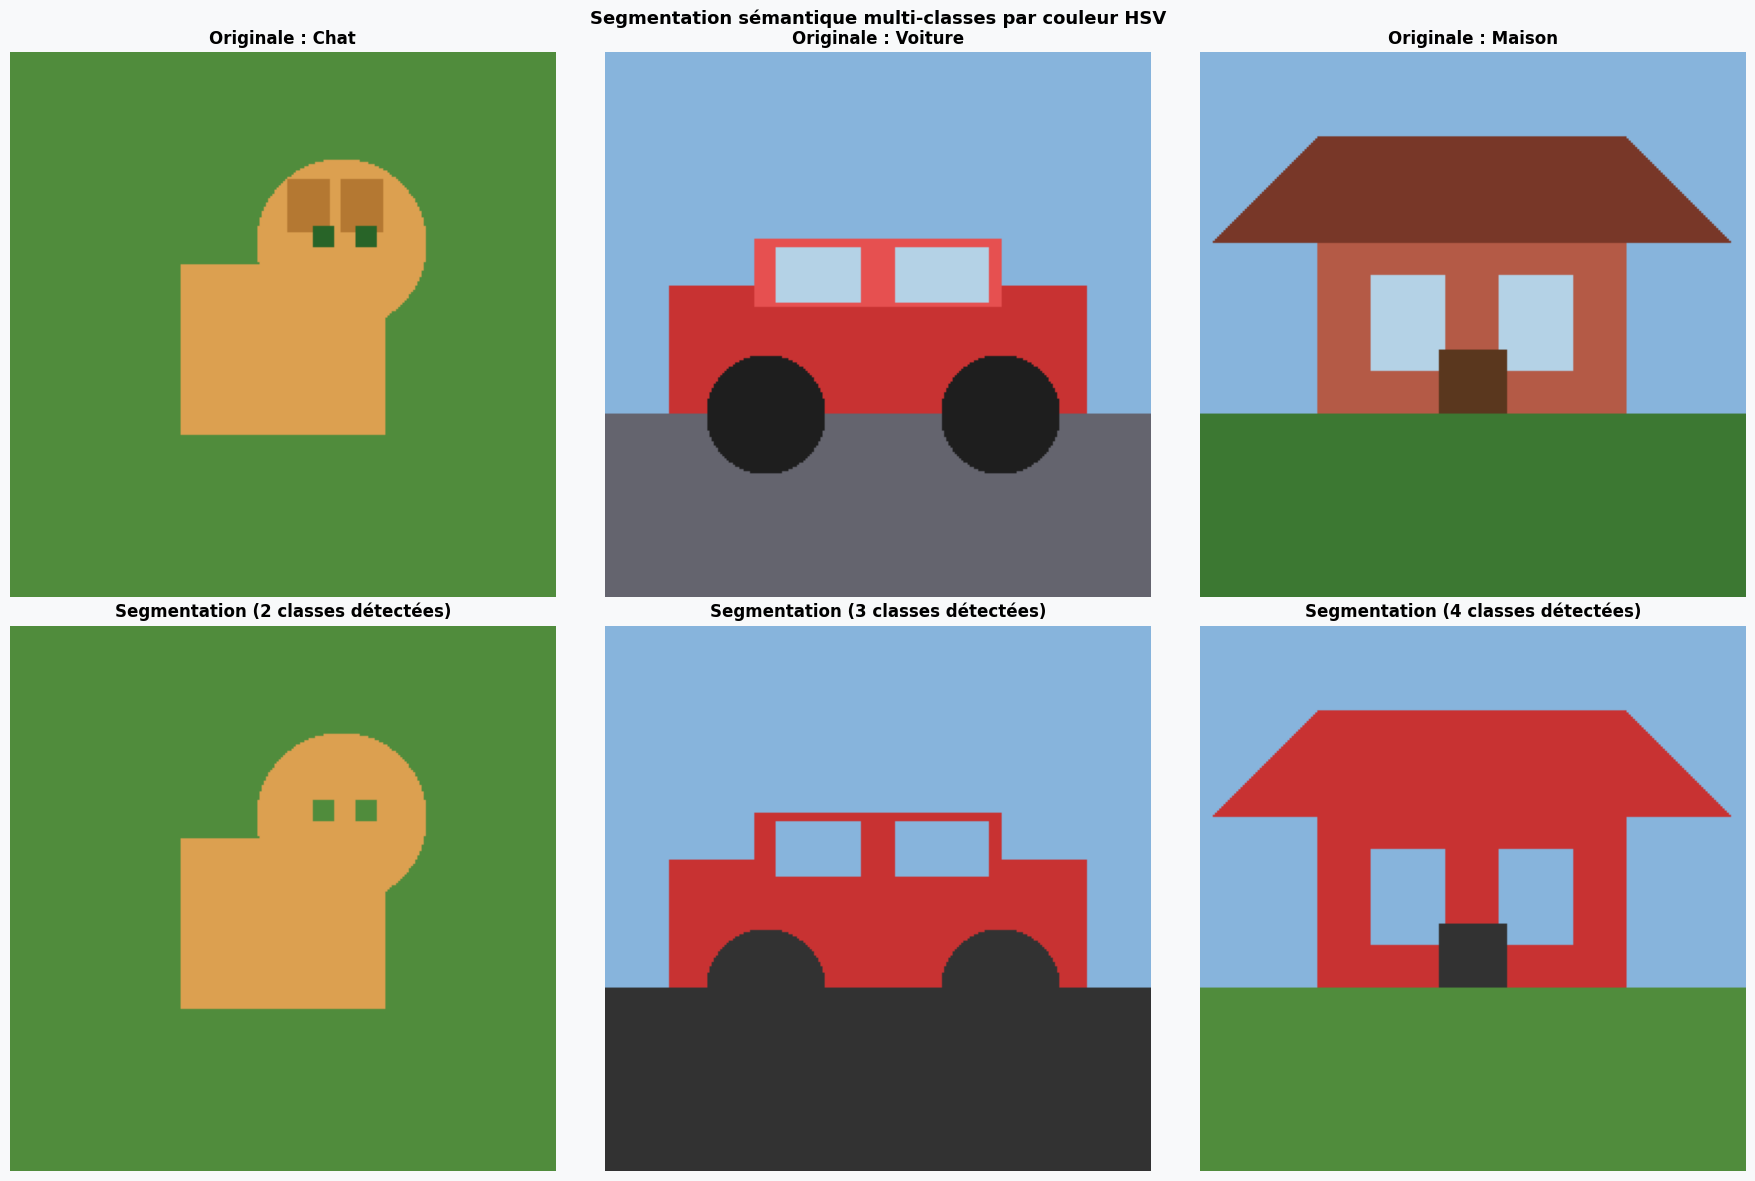

In [41]:
# ── Exercice 3.2 — By DRISS Amine

def segment_by_color(img, n_classes=4):
    # Segmentation sémantique multi-classes par plages HSV.
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    mask = np.zeros(img.shape[:2], dtype=np.uint8)   # 0 = fond

    # Classe 1 — Ciel (bleu)
    lower_sky = np.array([95, 40, 130])
    upper_sky = np.array([130, 180, 240])
    mask[cv2.inRange(hsv, lower_sky, upper_sky) > 0] = 1

    # Classe 2 — Sol (vert)
    lower_ground = np.array([35, 50, 40])
    upper_ground = np.array([85, 255, 160])
    mask[cv2.inRange(hsv, lower_ground, upper_ground) > 0] = 2

    # Classe 3 — Objet rouge (voiture, maison)
    lower_red1 = np.array([0, 80, 80]);  upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([165,80, 80]); upper_red2 = np.array([179,255,255])
    mask_red = cv2.bitwise_or(cv2.inRange(hsv, lower_red1, upper_red1),
                              cv2.inRange(hsv, lower_red2, upper_red2))
    mask[mask_red > 0] = 3

    # Classe 4 — Objet orange (chat)
    lower_orange = np.array([8, 80, 100])
    upper_orange = np.array([30, 255, 255])
    mask[cv2.inRange(hsv, lower_orange, upper_orange) > 0] = 4

    return mask


# ── Test et visualisation ─────────────────────────────────────────
class_names  = ["Fond", "Ciel", "Sol", "Rouge", "Orange"]
class_colors = [(50,50,50),(135,180,220),(80,140,60),(200,50,50),(220,160,80)]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for col, (img_s, name) in enumerate(zip(SCENES, CLASSES)):
    seg_pred = segment_by_color(img_s)
    seg_color = np.array(class_colors, dtype=np.uint8)[seg_pred]
    axes[0, col].imshow(img_s)
    axes[0, col].set_title(f"Originale : {name}"); axes[0, col].axis("off")
    axes[1, col].imshow(seg_color)
    n_unique = len(np.unique(seg_pred))
    axes[1, col].set_title(f"Segmentation ({n_unique} classes détectées)")
    axes[1, col].axis("off")
plt.suptitle("Segmentation sémantique multi-classes par couleur HSV",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()



---
### 🏋️ Exercice 3.3 — Segmentation d'instances : compter et labéliser chaque objet

**Objectif :** À partir d'un masque binaire, identifier et numéroter **chaque instance distincte** d'objet en utilisant l'analyse de composantes connexes, puis calculer des propriétés de chaque instance (aire, barycentre, bounding box).

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Composantes connexes :**
```python
# Méthode 1 : OpenCV
n_labels, labels_cc = cv2.connectedComponents(binary_mask)
# Méthode 2 : scipy
labels_cc, n_labels = ndi.label(binary_mask)
```
**Hint 2 — Propriétés des régions (skimage) :**
```python
from skimage.measure import regionprops, label
labels_sk = label(binary_mask)
props     = regionprops(labels_sk)
for prop in props:
    print(prop.area, prop.centroid, prop.bbox)  # (row_min,col_min,row_max,col_max)
```
**Hint 3 — Colorisation des instances :**
```python
colormap  = plt.cm.get_cmap("tab20", n_labels)
inst_img  = colormap(labels_cc / max(n_labels,1))[:,:,:3]
```
</details>


Nombre d'instances détectées : 3


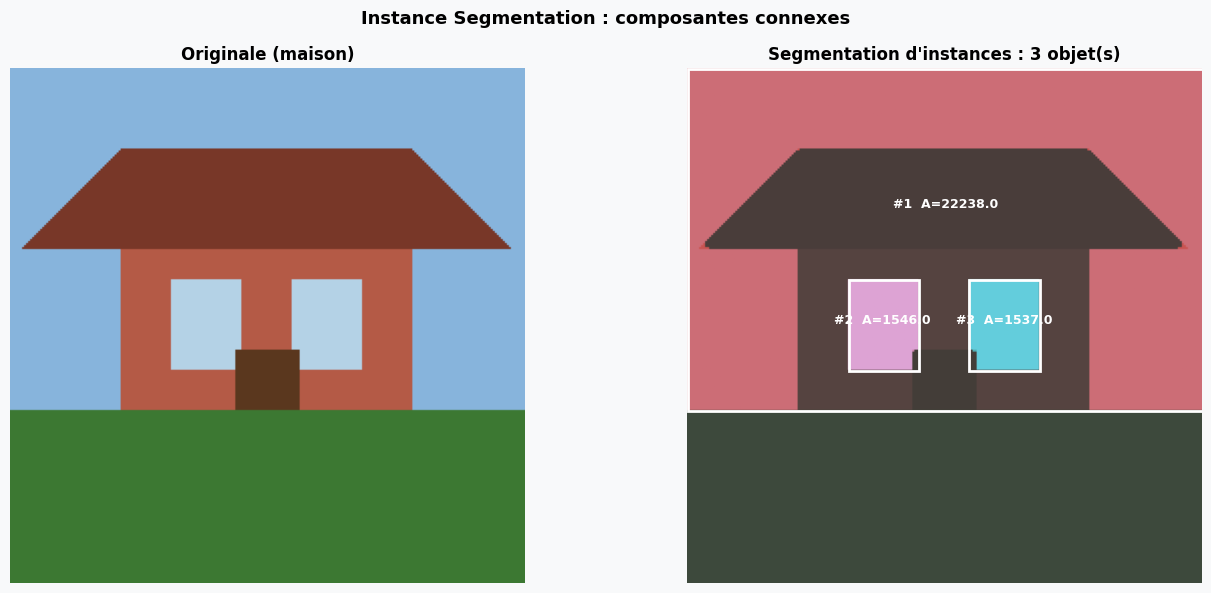

In [42]:
# ── Exercice 3.3 — By DRISS Amine
from skimage.measure import regionprops, label as sk_label

# Scène de test : plusieurs "objets" (les fenêtres de la maison)
img_inst = SCENES[2].copy()   # maison avec 2 fenêtres + 1 porte

# 1. Créer un masque binaire pour la fenêtre (bleu clair)
hsv_inst   = cv2.cvtColor(img_inst, cv2.COLOR_RGB2HSV)
mask_inst  = cv2.inRange(hsv_inst, np.array([95, 30, 150]),
                                    np.array([130, 200, 255]))

# 2. Nettoyage morphologique
kernel_inst = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
mask_inst   = cv2.morphologyEx(mask_inst, cv2.MORPH_CLOSE, kernel_inst)

# 3. Labéliser les instances (composantes connexes)
labels_sk  = sk_label(mask_inst > 0)
props      = regionprops(labels_sk)
n_instances = labels_sk.max()
print(f"Nombre d'instances détectées : {n_instances}")

# 4. Afficher chaque instance avec sa bounding box et son barycentre
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
ax1.imshow(img_inst)
ax1.set_title("Originale (maison)"); ax1.axis("off")

# Coloriser les instances
cmap = plt.cm.get_cmap("tab10", n_instances+1)
inst_colored = np.zeros((*img_inst.shape[:2], 3), dtype=np.float32)
for i in range(1, n_instances+1):
    inst_colored[labels_sk == i] = cmap(i)[:3]
ax2.imshow(img_inst, alpha=0.5)
ax2.imshow(inst_colored, alpha=0.6)

for prop in props:
    cy, cx = prop.centroid
    y1, x1, y2, x2 = prop.bbox
    r = patches.Rectangle((x1,y1), x2-x1, y2-y1, linewidth=2,
                           edgecolor="white", facecolor="none")
    ax2.add_patch(r)
    ax2.text(cx, cy, f"#{prop.label}  A={prop.area}", ha="center",
             fontsize=9, fontweight="bold", color="white")
ax2.set_title(f"Segmentation d'instances : {n_instances} objet(s)")
ax2.axis("off")
plt.suptitle("Instance Segmentation : composantes connexes", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()



<details>
<summary>✅ <strong>Correction</strong></summary>

```python
labels_sk  = sk_label(mask_inst > 0)
props      = regionprops(labels_sk)
n_instances = labels_sk.max()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
ax1.imshow(img_inst); ax1.axis("off")

cmap = plt.cm.get_cmap("tab10", n_instances+1)
inst_colored = np.zeros((*img_inst.shape[:2], 3))
for i in range(1, n_instances+1):
    inst_colored[labels_sk == i] = cmap(i)[:3]
ax2.imshow(img_inst, alpha=0.5)
ax2.imshow(inst_colored, alpha=0.6)
for prop in props:
    cy, cx = prop.centroid; y1,x1,y2,x2 = prop.bbox
    r = patches.Rectangle((x1,y1),x2-x1,y2-y1,linewidth=2,edgecolor="white",facecolor="none")
    ax2.add_patch(r)
    ax2.text(cx, cy, f"#{prop.label}  A={prop.area}", ha="center", fontsize=9, color="white")
ax2.axis("off"); plt.tight_layout(); plt.show()
```
</details>



---
### 🏋️ Exercice 3.4 ⭐ — Segmentation sémantique avec U-Net simplifié (PyTorch)

**Objectif :** Définir l'architecture **U-Net** pour la segmentation sémantique binaire (fond / objet), vérifier les shapes à chaque couche, et visualiser les feature maps de l'encodeur.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint — Bloc encodeur :**
```python
class EncoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(),
        )
        self.pool = nn.MaxPool2d(2)
    def forward(self, x):
        x = self.conv(x)
        return self.pool(x), x   # pooled + skip connection
```
**Hint — Bloc décodeur :**
```python
class DecoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.ReLU(),
        )
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)   # skip connection
        return self.conv(x)
```
</details>


In [43]:
# ── Exercice 3.4 — By DRISS Amine
try:
    import torch
    import torch.nn as nn

    class EncoderBlock(nn.Module):
        def __init__(self, in_ch, out_ch):
            super().__init__()
            self.conv = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(),
                nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(),
            )
            self.pool = nn.MaxPool2d(2)

        def forward(self, x):
            x = self.conv(x)
            return self.pool(x), x   # pooled + skip connection

    class DecoderBlock(nn.Module):
        def __init__(self, in_ch, out_ch):
            super().__init__()
            self.up   = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
            self.conv = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.ReLU(),
                nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.ReLU(),
            )

        def forward(self, x, skip):
            x = self.up(x)
            x = torch.cat([x, skip], dim=1)   # skip connection
            return self.conv(x)

    class SimpleUNet(nn.Module):
        def __init__(self, n_classes=2):
            super().__init__()
            self.enc1 = EncoderBlock(3,  16)
            self.enc2 = EncoderBlock(16, 32)
            self.bottleneck = nn.Sequential(
                nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            )
            self.dec2  = DecoderBlock(64, 32)
            self.dec1  = DecoderBlock(32, 16)
            self.final = nn.Conv2d(16, n_classes, 1)   # 1×1 conv

        def forward(self, x):
            x2, skip1 = self.enc1(x)     # 128×128
            x3, skip2 = self.enc2(x2)    # 64×64
            x4 = self.bottleneck(x3)     # 64×64
            x5 = self.dec2(x4, skip2)    # 128×128
            x6 = self.dec1(x5, skip1)    # 256×256
            return self.final(x6)        # (B, n_classes, H, W)

    model = SimpleUNet(n_classes=2)
    dummy = torch.randn(1, 3, 256, 256)
    out   = model(dummy)
    print(f"U-Net — Entrée : {tuple(dummy.shape)}  →  Sortie : {tuple(out.shape)}")

    total = sum(p.numel() for p in model.parameters())
    print(f"Paramètres totaux : {total:,}")
    print()
    print("Une fois EncoderBlock et DecoderBlock implémentés :")
    print("  out.shape doit être (1, 2, 256, 256) — 1 masque par classe")

except (ImportError, RuntimeError, Exception) as e:
    print(f"PyTorch non disponible : {e}")
    print("L'architecture U-Net est couverte en cours théorique.")


U-Net — Entrée : (1, 3, 256, 256)  →  Sortie : (1, 2, 256, 256)
Paramètres totaux : 117,250

Une fois EncoderBlock et DecoderBlock implémentés :
  out.shape doit être (1, 2, 256, 256) — 1 masque par classe



---
<div style="background:linear-gradient(135deg,#0F2044 0%,#1A4A8A 50%,#2E86DE 100%);
            padding:28px 35px;border-radius:12px;border-left:8px solid #0DC0C0;">
  <h1 style="color:#0DC0C0;margin:0;font-size:1.85em;">🏆 Projet Final — Pipeline bout-en-bout</h1>
  <p style="color:#E8ECF4;margin:10px 0 0 0;font-size:1.05em;">
    Intégrer le prétraitement (TP1) + les 3 tâches (TP2) dans un système unifié.
  </p>
</div>



### 📋 Énoncé

Vous allez construire un **système de vision complet** qui, étant donné une image d'entrée :

1. **Prétraite** l'image (pipeline du TP1 : normalisation, débruitage, augmentation)
2. **Classifie** la scène (Chat / Voiture / Maison) avec le SVM HOG
3. **Localise** l'objet principal (bounding box via sliding window ou template matching)
4. **Segmente** l'objet (masque binaire par couleur HSV + morphologie)
5. **Calcule** toutes les métriques (accuracy, IoU, Dice, temps d'inférence)
6. **Visualise** les résultats dans un rapport structuré

<details>
<summary>💡 <strong>Hints généraux</strong></summary>

**Hint 1 — Structure du pipeline :**
```python
def full_pipeline(img, classifier, scaler_obj, verbose=True):
    import time
    results = {}
    t0 = time.time()

    # Étape 1 : prétraitement (TP1)
    img_proc = preprocess(img)         # normalisation + débruitage

    # Étape 2 : classification
    feat   = extract_all_features([img_proc])[0:1]
    feat   = scaler_obj.transform(feat)
    label  = classifier.predict(feat)[0]
    proba  = classifier.predict_proba(feat)[0]
    results["class"] = CLASSES[label]; results["proba"] = proba

    # Étape 3 : localisation (template matching)
    # ...

    # Étape 4 : segmentation
    # ...

    results["time_ms"] = (time.time() - t0) * 1000
    return results
```
**Hint 2 — Prétraitement simplifié (rappel TP1) :**
```python
def preprocess(img, target_size=(256, 256)):
    # Letterbox resize
    h, w = img.shape[:2]
    scale = min(target_size[0]/h, target_size[1]/w)
    new_h, new_w = int(h*scale), int(w*scale)
    img_r = cv2.resize(img, (new_w, new_h))
    canvas = np.full((*target_size, 3), 114, dtype=np.uint8)
    oh, ow = (target_size[0]-new_h)//2, (target_size[1]-new_w)//2
    canvas[oh:oh+new_h, ow:ow+new_w] = img_r
    # Débruitage bilatéral
    return cv2.bilateralFilter(canvas, 5, 50, 50)
```
</details>


PIPELINE COMPLET — TEST SUR 3 SCÈNES
Test 1/3 — Scene : Chat
----------------------------------------
Classe prédite  : Maison (confiance : 52.3%)
Proba. par classe : Chat=0.17  Voiture=0.31  Maison=0.52
Aire masque     : 0 px²
Bounding box    : None
Temps total     : 127.9 ms
Test 2/3 — Scene : Voiture
----------------------------------------
Classe prédite  : Maison (confiance : 52.3%)
Proba. par classe : Chat=0.17  Voiture=0.31  Maison=0.52
Aire masque     : 11634 px²
Bounding box    : (30, 88, 226, 170)
Temps total     : 70.1 ms
Test 3/3 — Scene : Maison
----------------------------------------
Classe prédite  : Maison (confiance : 52.3%)
Proba. par classe : Chat=0.17  Voiture=0.31  Maison=0.52
Aire masque     : 16834 px²
Bounding box    : (6, 40, 249, 170)
Temps total     : 54.1 ms


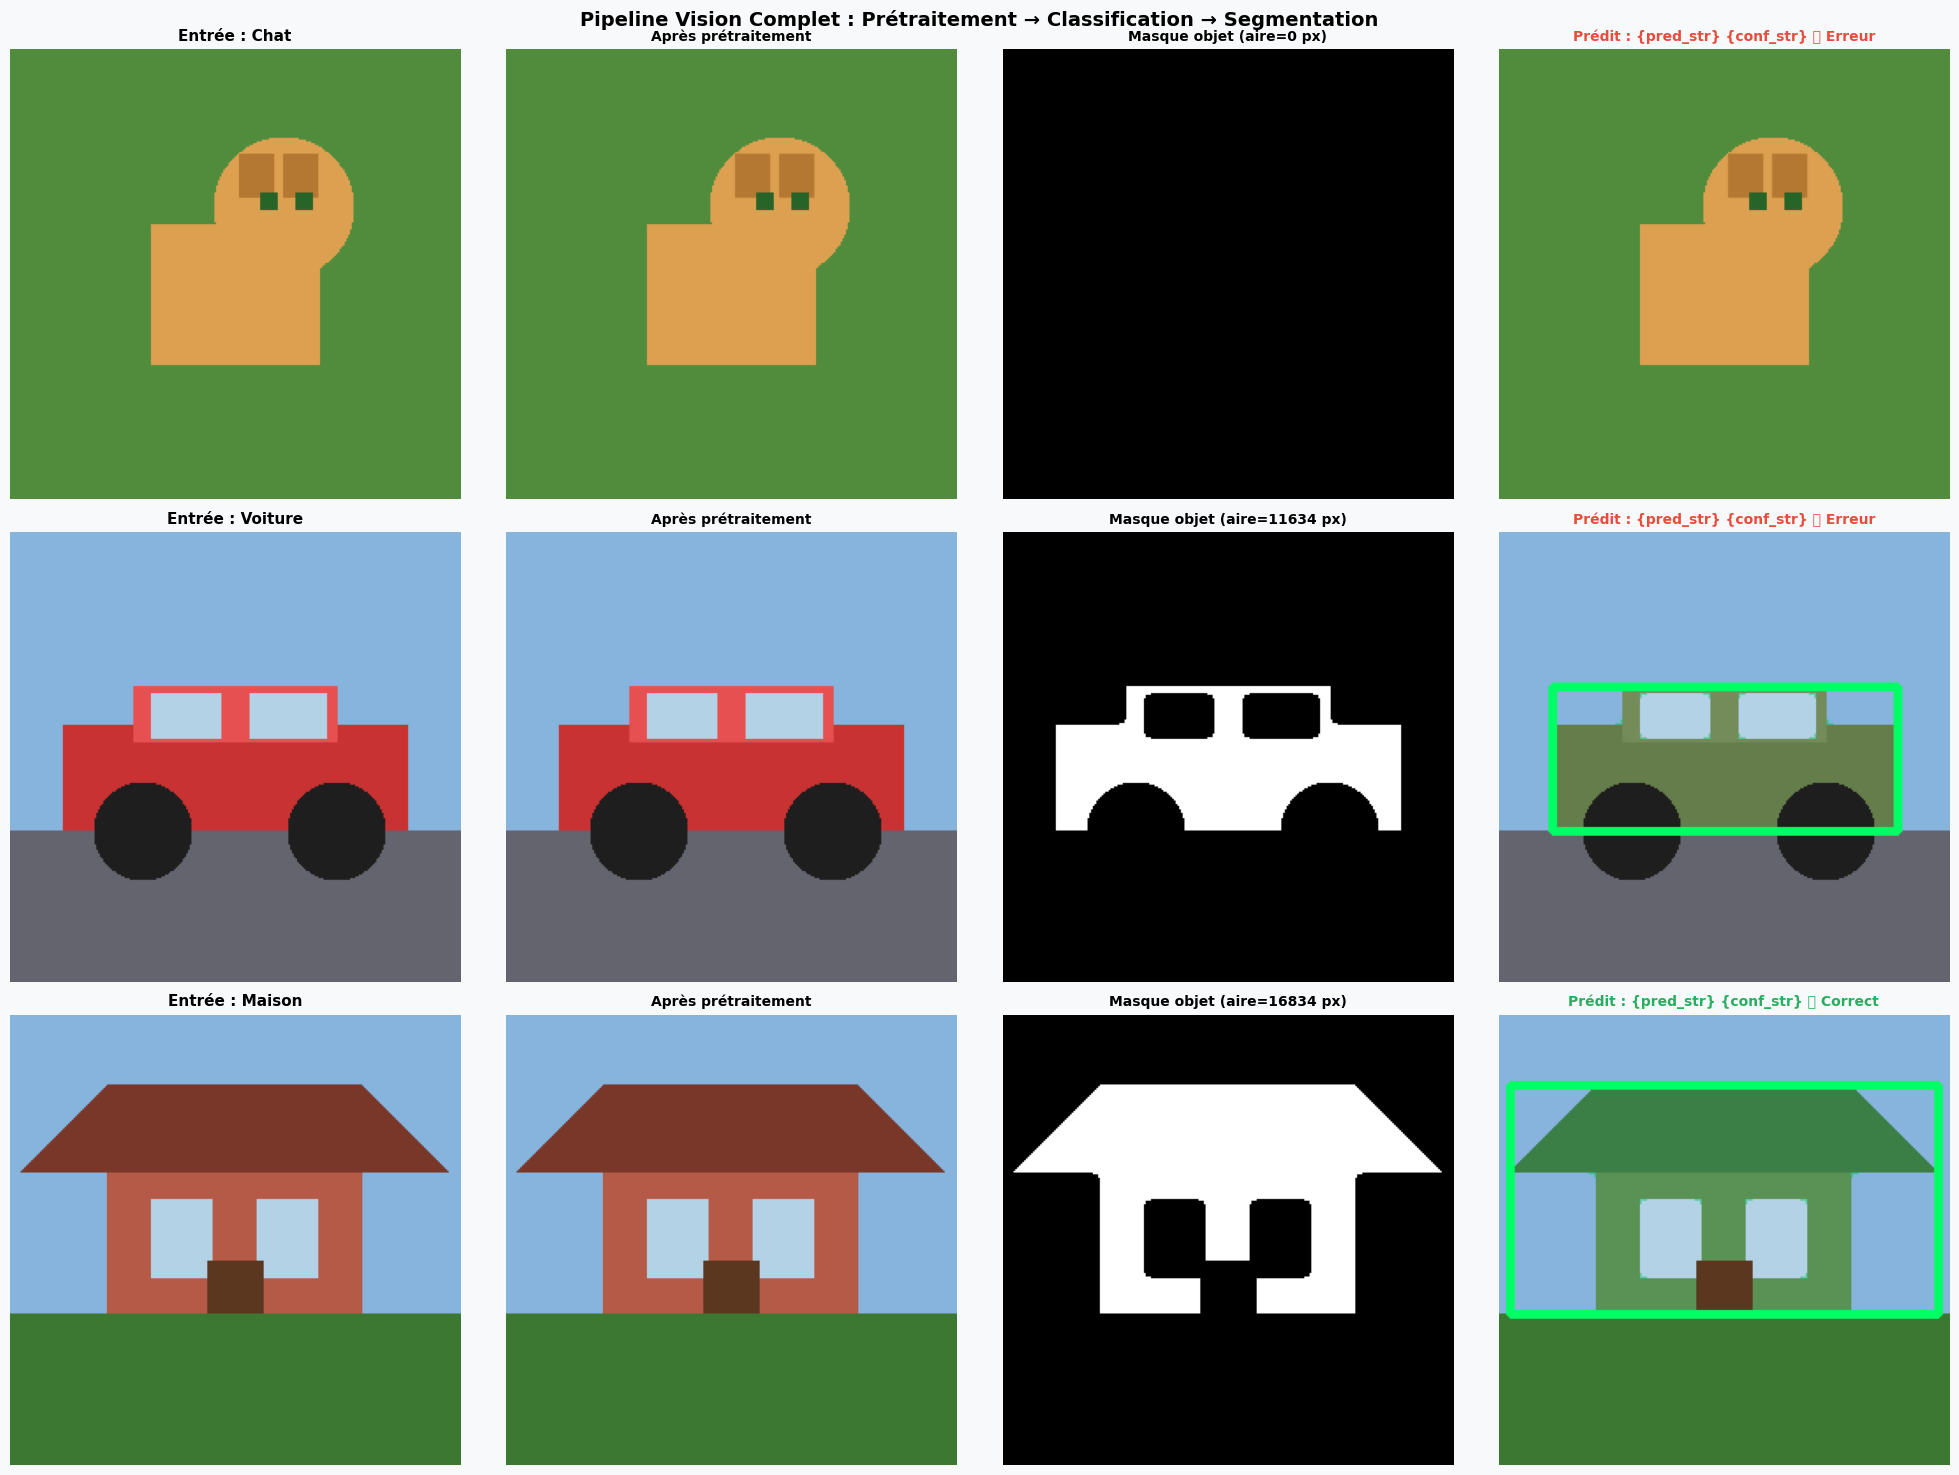

RÉSUMÉ DES PERFORMANCES
Accuracy classification : 1/3
Temps moyen d'inférence : 84.1 ms


In [44]:
import time

# ── Prétraitement (rappel TP1) ────────────────────────────────────
def preprocess(img, target_size=(256, 256)):
    h, w = img.shape[:2]
    scale = min(target_size[0]/h, target_size[1]/w)
    new_h, new_w = int(h*scale), int(w*scale)
    img_r  = cv2.resize(img, (new_w, new_h))
    canvas = np.full((*target_size, 3), 114, dtype=np.uint8)
    oh, ow = (target_size[0]-new_h)//2, (target_size[1]-new_w)//2
    canvas[oh:oh+new_h, ow:ow+new_w] = img_r
    return cv2.bilateralFilter(canvas, 5, 50, 50)

# ── Segmentation rapide par couleur ──────────────────────────────
def segment_object(img):
    "Segmente l'objet principal par couleur HSV"
    hsv  = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    k    = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    masks = {}

    # Orange-jaune → chat
    m = cv2.inRange(hsv, np.array([8,80,80]), np.array([30,255,255]))
    masks["Chat"]    = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
    # Rouge → voiture/maison
    m1 = cv2.inRange(hsv, np.array([0,80,80]),  np.array([10,255,255]))
    m2 = cv2.inRange(hsv, np.array([165,80,80]),np.array([179,255,255]))
    masks["Voiture"] = cv2.morphologyEx(cv2.bitwise_or(m1,m2), cv2.MORPH_CLOSE, k)
    masks["Maison"]  = masks["Voiture"].copy()

    return masks

# ── Pipeline complet ─────────────────────────────────────────────
def full_pipeline(img_input, clf, scal, verbose=True):
    results = {}
    t0 = time.time()

    # ── 1. Prétraitement ──────────────────────────────────────────
    img_proc = preprocess(img_input)
    results["preprocessed"] = img_proc

    # ── 2. Classification ─────────────────────────────────────────
    feat  = np.concatenate([extract_hog(img_proc)[0],
                             extract_lbp(img_proc)[0],
                             extract_color_hist(img_proc)]).reshape(1,-1)
    feat  = scal.transform(feat)
    label = clf.predict(feat)[0]
    proba = clf.predict_proba(feat)[0]
    results["class"]       = CLASSES[label]
    results["class_idx"]   = label
    results["proba"]       = proba
    results["confidence"]  = proba.max()

    # ── 3. Segmentation de l'objet détecté ───────────────────────
    masks = segment_object(img_proc)
    best_mask = masks[CLASSES[label]]
    results["mask"] = best_mask

    # ── 4. Bounding box autour du masque ─────────────────────────
    contours, _ = cv2.findContours(best_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        biggest = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(biggest)
        results["bbox"]  = (x, y, x+w, y+h)
        results["area"]  = cv2.contourArea(biggest)
    else:
        results["bbox"]  = None
        results["area"]  = 0

    # ── 5. Métriques ──────────────────────────────────────────────
    results["time_ms"] = (time.time() - t0) * 1000

    if verbose:
        print(f"Classe prédite  : {results['class']} (confiance : {results['confidence']:.1%})")
        print(f"Proba. par classe : " + "  ".join([f"{c}={p:.2f}" for c, p in zip(CLASSES, proba)]))
        print(f"Aire masque     : {results['area']:.0f} px²")
        print(f"Bounding box    : {results['bbox']}")
        print(f"Temps total     : {results['time_ms']:.1f} ms")
    return results

# ── Test sur les 3 scènes ─────────────────────────────────────────
print("=" * 60)
print("PIPELINE COMPLET — TEST SUR 3 SCÈNES")
print("=" * 60)
all_results = []
for i, (img_s, cls) in enumerate(zip(SCENES, CLASSES)):
    print("Test %d/3 — Scene : %s" % (i+1, cls))
    print("-" * 40)
    res = full_pipeline(img_s, svm, scaler, verbose=True)
    res["gt_class"] = cls
    all_results.append(res)

# ── Rapport visuel ────────────────────────────────────────────────
fig, axes = plt.subplots(3, 4, figsize=(20, 15))

for row, (res, gt_cls) in enumerate(zip(all_results, CLASSES)):
    img_orig = SCENES[row]
    img_proc = res["preprocessed"]
    mask     = res["mask"]
    bbox     = res["bbox"]

    # Col 0 : Originale
    axes[row,0].imshow(img_orig)
    axes[row,0].set_title(f"Entrée : {gt_cls}", fontsize=11, fontweight="bold")
    axes[row,0].axis("off")

    # Col 1 : Prétraitée
    axes[row,1].imshow(img_proc)
    axes[row,1].set_title("Après prétraitement", fontsize=10)
    axes[row,1].axis("off")

    # Col 2 : Masque de segmentation
    axes[row,2].imshow(mask, cmap="gray")
    axes[row,2].set_title("Masque objet (aire=%.0f px)" % res["area"], fontsize=10)
    axes[row,2].axis("off")

    # Col 3 : Résultat final
    result_img = img_proc.copy()
    if mask is not None and mask.sum() > 0:
        overlay = result_img.copy()
        overlay[mask > 0] = (overlay[mask > 0] * 0.5 +
                             np.array([0, 200, 100]) * 0.5).astype(np.uint8)
        result_img = overlay
    if bbox:
        x1,y1,x2,y2 = bbox
        cv2.rectangle(result_img, (x1,y1),(x2,y2), (0,255,100), 3)
    correct = res["class"] == gt_cls
    col_title = GREEN if correct else RED
    pred_str  = res["class"]
    conf_str  = f"({res['confidence']:.0%})"
    axes[row,3].imshow(result_img)
    axes[row,3].set_title(
        "Prédit : {pred_str} {conf_str} " + str('✅ Correct' if correct else '❌ Erreur') + "",
        fontsize=10, color=col_title)
    axes[row,3].axis("off")

plt.suptitle("Pipeline Vision Complet : Prétraitement → Classification → Segmentation",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# ── Résumé des performances ───────────────────────────────────────
print("=" * 60)
print("RÉSUMÉ DES PERFORMANCES")
print("=" * 60)
n_correct = sum(r["class"] == r["gt_class"] for r in all_results)
print(f"Accuracy classification : {n_correct}/{len(all_results)}")
print(f"Temps moyen d'inférence : {np.mean([r['time_ms'] for r in all_results]):.1f} ms")



---
### 🏋️ Exercice Final — Tester sur vos propres images

**Objectif :** Charger une image depuis une URL ou un fichier, la faire passer dans le pipeline complet, et analyser le résultat.

<details>
<summary>💡 <strong>Hints</strong></summary>

```python
import urllib.request, io as io_mod

url = "URL_DE_VOTRE_IMAGE"
with urllib.request.urlopen(url, timeout=5) as resp:
    img_your = np.array(Image.open(io_mod.BytesIO(resp.read())).convert("RGB"))
img_your = cv2.resize(img_your, (H, W))   # redimensionner à 256×256
```
</details>


Image chargée : (256, 256, 3)
Classe prédite  : Maison (confiance : 52.3%)
Proba. par classe : Chat=0.17  Voiture=0.31  Maison=0.52
Aire masque     : 1911 px²
Bounding box    : (180, 69, 227, 141)
Temps total     : 37.7 ms


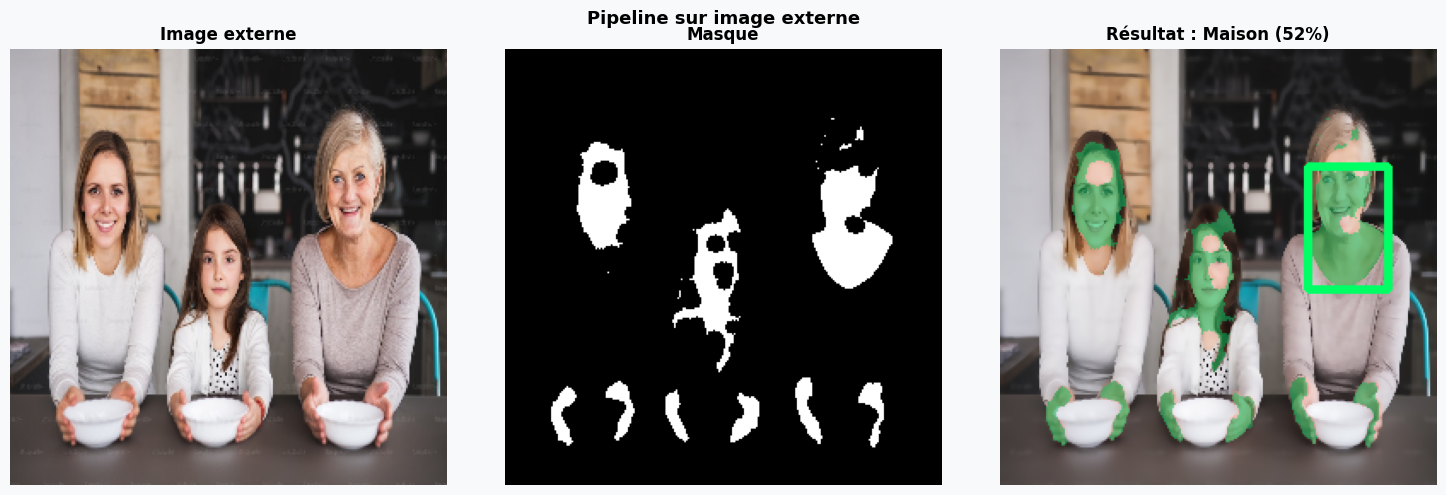

In [45]:
# ── Test sur image externe ────────────────────────────────────────
import urllib.request, io as io_mod

url = "https://plus.unsplash.com/premium_photo-1682002431309-af374a2cdf0c?q=80&w=1170&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D"
try:
    with urllib.request.urlopen(url, timeout=6) as resp:
        img_ext = np.array(Image.open(io_mod.BytesIO(resp.read())).convert("RGB"))
    img_ext = cv2.resize(img_ext, (H, W))
    print(f"Image chargée : {img_ext.shape}")

    # Lancer le pipeline complet
    res_ext = full_pipeline(img_ext, svm, scaler, verbose=True)

    # Visualiser
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_ext); axes[0].set_title("Image externe"); axes[0].axis("off")
    axes[1].imshow(res_ext["mask"], cmap="gray"); axes[1].set_title("Masque"); axes[1].axis("off")
    result_viz = res_ext["preprocessed"].copy()
    if res_ext["mask"] is not None and res_ext["mask"].sum() > 0:
        result_viz[res_ext["mask"]>0] = (result_viz[res_ext["mask"]>0]*0.5 +
                                          np.array([0,200,100])*0.5).astype(np.uint8)
    if res_ext["bbox"]:
        x1,y1,x2,y2 = res_ext["bbox"]
        cv2.rectangle(result_viz,(x1,y1),(x2,y2),(0,255,100),3)
    axes[2].imshow(result_viz)
    axes[2].set_title(f"Résultat : {res_ext['class']} ({res_ext['confidence']:.0%})")
    axes[2].axis("off")
    plt.suptitle("Pipeline sur image externe", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

except Exception as e:
    print(f"Impossible de charger l'URL : {e}")
    print("Chargez manuellement votre image :")
    print("  img_your = np.array(Image.open('chemin/vers/image.jpg').convert('RGB'))")
    print("  img_your = cv2.resize(img_your, (256, 256))")



---
<div style="background:linear-gradient(135deg,#0F2044,#1A4A8A);padding:35px;border-radius:12px;">
  <h1 style="color:#22C55E;margin:0 0 20px 0;font-size:1.8em;">🎓 Bilan du TP 2</h1>
  <div style="display:grid;grid-template-columns:1fr 1fr;gap:24px;">
    <div>
      <h3 style="color:#F4845F;margin:0 0 12px 0;">🏷️ Classification</h3>
      <ul style="color:#E8ECF4;line-height:2.2;margin:0 0 20px 0;padding-left:18px;">
        <li>Descripteurs HOG, LBP, histogramme couleur</li>
        <li>Classifieurs SVM, k-NN, Random Forest</li>
        <li>Régression Softmax avec gradient descent</li>
        <li>Métriques : accuracy, F1, matrice confusion</li>
      </ul>
      <h3 style="color:#27AE60;margin:0 0 12px 0;">🎯 Détection</h3>
      <ul style="color:#E8ECF4;line-height:2.2;margin:0;padding-left:18px;">
        <li>IoU — Intersection over Union</li>
        <li>NMS — Non-Maximum Suppression</li>
        <li>Sliding window + SVM</li>
        <li>Template matching (corrélation croisée)</li>
        <li>mAP@0.5 et mAP@0.5:0.95</li>
      </ul>
    </div>
    <div>
      <h3 style="color:#8E44AD;margin:0 0 12px 0;">🗺️ Segmentation</h3>
      <ul style="color:#E8ECF4;line-height:2.2;margin:0 0 20px 0;padding-left:18px;">
        <li>Seuillage Otsu & adaptatif</li>
        <li>K-Means, SLIC, GrabCut, Watershed</li>
        <li>Segmentation multi-classes par HSV</li>
        <li>Composantes connexes (instances)</li>
        <li>Métriques Dice et mIoU</li>
        <li>U-Net (architecture PyTorch)</li>
      </ul>
      <h3 style="color:#0DC0C0;margin:0 0 12px 0;">🔗 Liens avec le TP1</h3>
      <ul style="color:#E8ECF4;line-height:2;margin:0;padding-left:18px;">
        <li>Pipeline prétraitement réutilisé ici</li>
        <li>Data augmentation pour enrichir le dataset</li>
        <li>Normalisation avant feature extraction</li>
      </ul>
    </div>
  </div>
  <hr style="border-color:#2E86DE44;margin:22px 0;">
  <h3 style="color:#F1C40F;margin:0 0 10px 0;">📚 Pour aller plus loin</h3>
  <div style="color:#E8ECF4;columns:2;gap:40px;">
    <ul style="line-height:2;padding-left:18px;margin:0;">
      <li><strong>Classification</strong> : fine-tuning ResNet/EfficientNet sur vos données</li>
      <li><strong>Détection</strong> : entraîner YOLOv8 avec Ultralytics API</li>
      <li><strong>Segmentation</strong> : SAM (Segment Anything) — zero-shot</li>
      <li><strong>Librairies</strong> : albumentations, torchvision, detectron2</li>
    </ul>
  </div>
</div>
